# Pennycress: where the water goes, and how big each plant will get

This notebook is the whole analysis in one place, from the raw files to the final prediction model. You can read it from top to bottom like a report: every step has a short explanation, then the code, then a chart or table.

It has two halves.

**Part A · What uses the water?**
Each pot is weighed several times a day. Between two weigh-ins it loses water in two ways:
- the wet soil dries out (**soil evaporation**), which happens whether or not there is a plant;
- the plant pulls water up through its roots and lets it out through its leaves (**plant use**).

We work out how much of the loss is soil and how much is plant, in the daytime, the evening and overnight.

**Part B · How big will each plant get?**
Using only what we know about a plant up to **April 25**, we try to predict how big its leaves will be at the end of the experiment (**May 6–7**). We start with almost nothing (water use only), add one kind of information at a time, and check after every addition whether the predictions got better.

**What we found, in short**
- At first (Apr 21–23) almost all the water a pot loses is the soil drying out. The seedlings are too small to matter (about 2%). A week later (Apr 27–29) the plant takes 56% of it.
- Pots lose the most water during the day, for two reasons. Bare soil dries 2.7 times faster by day than at night, and each piece of leaf uses 4.1 times more water by day, because leaves open their pores in the light.
- The metal mainly decides **whether a plant grows at all**: only 43–50% of pots grew at the two highest levels, against 77–92% at the others. Plants that did grow at high metal were only somewhat smaller. We found no clear effect of the metal on how fast bare soil dries, or (once plant size is allowed for) on how much water a piece of leaf uses.
- Water use alone gives a rough guess of the final size: the predictions miss by 20.7 on average, against 28.1 for guessing the same average size for every plant.
- The plant's own recent growth, measured from the photos, is far more useful. The final model misses by **7.28** on average, on plants it never saw while learning. It does not use where the pot sat on the shelves.
- Once the photos are in, the water numbers stop helping, so the final model leaves them out.

**Contents**
1. Loading and cleaning the data
2. Part A: weigh-in gaps · soil evaporation · soil vs plant · checks · why daytime · metal
3. Part B: the task · how we score · Steps 0 to 9 · the final model · how early we can predict
4. Summary and next steps


In [ ]:
# The tools we use:
#   pandas for tables, numpy for maths, matplotlib for charts,
#   scipy for fitting growth curves and simple statistical tests,
#   statsmodels for one size-aware comparison, scikit-learn for the prediction models.
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from PIL import Image
from scipy.optimize import curve_fit
from scipy.stats import kruskal, spearmanr
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

warnings.filterwarnings("ignore")   # hide routine library warnings so the output stays readable

DATA = Path("..")                   # the export folder (this notebook sits inside work2/)
OUT = Path("outputs")               # where the result tables are saved
OUT.mkdir(exist_ok=True)

# One look for every chart: a light grid, no box around the plot, titles on the left.
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
    "legend.frameon": False,
})

# Colours used throughout:
#   blue = the plant (or a pot that grew), orange = the soil (or a pot that never grew), grey = everything else.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, INK, MUTED = "#a3a29c", "#0b0b0b", "#52514e"
PLANT, SOIL = BLUE, ORANGE
STATUS_COLORS = {"never grew": ORANGE, "stunted": GREY, "grew": BLUE}

# The three kinds of weigh-in gap (explained in section 2). Darker blue = more light during the gap.
GAPS = ["daytime", "evening", "overnight"]
GAP_COLORS = {"daytime": "#104281", "evening": "#3987e5", "overnight": "#86b6ef"}


def two_decimals(value):
    # Show a number with 2 decimals, without the odd-looking "-0.00".
    text = f"{value:.2f}"
    return "0.00" if text == "-0.00" else text

## 1 · Loading and cleaning the data

### 1a · The weigh-ins

A machine visits every pot several times a day. It weighs the pot, then adds water until the pot is back at its target weight. Each row in the weights file is one of those visits:
- `weight_g` is the pot's weight **before** the machine adds water;
- `weight_after_watering_g` is the weight **after** it has added water.

Before using the file we clean three small problems:
- A full pot weighs about 130 to 210 g, so a reading of 0 g, or of 500 g and above, can only be a scale glitch. Those rows are removed.
- A few pots appear twice at the exact same moment. The copies are removed.
- One after-watering weight is 0 g. That is a missing reading, not an empty pot, so we blank it out instead of trusting it.

In [ ]:
# Read every weigh-in. One row = one pot weighed (and then watered) once.
w = pd.read_parquet(DATA / "plant-weights.parquet")
w["datetime"] = pd.to_datetime(w["datetime"])
n_start = len(w)

# Readings that can only be scale glitches.
glitch = (w.weight_g <= 0) | (w.weight_g >= 500)

# Remove the glitches, remove any pot weighed twice at the same moment,
# and sort so that each pot's weigh-ins are in time order.
w = w[~glitch].drop_duplicates(["plant_id", "datetime"]).sort_values(["plant_id", "datetime"])

# An after-watering weight of 0 g is a missing reading: blank it out.
n_zero_after = (w.weight_after_watering_g <= 0).sum()
w.loc[w.weight_after_watering_g <= 0, "weight_after_watering_g"] = np.nan

print(f"{n_start:,} weigh-ins in the file")
print(f"  removed {glitch.sum()} scale glitches and {n_start - glitch.sum() - len(w)} duplicates")
print(f"  {n_zero_after} after-watering weight of 0 g blanked out")
print(f"{len(w):,} weigh-ins left, {w.plant_id.nunique()} pots, {w.datetime.min():%b %d} to {w.datetime.max():%b %d}")

25,752 weigh-ins in the file
  removed 7 scale glitches and 12 duplicates
  1 after-watering weight of 0 g blanked out
25,733 weigh-ins left, 360 pots, Apr 06 to May 07


### 1b · The photos and the experiment design

Each pot is also photographed from above several times a day. Image analysis turns each photo into numbers: the leaf area, the shape of the plant and its colour. When the analysis finds no plant in a photo, the leaf area is blank. We count that as **0**, because there really is nothing green there.

The file calls the leaf-area unit "mm²", but the numbers look too small for that, so in this notebook we just say **leaf-area units**.

We also load the experiment design: which genotype each pot holds and which metal level it got.

In [ ]:
# Columns we need from the photo file:
#   leaf area; the plant's shape and colour (used in Part B);
#   and where each pot sits inside the tray photo (used to draw boxes on one photo below).
SHAPE = ["perimeter_mm", "convex_area_mm2", "plant_roundness_index", "compactness_index", "bbox_height_mm", "bbox_width_mm"]
COLOUR = ["hue_median", "saturation_median", "lightness_median", "green-red_median", "blue-yellow_median",
          "ngrdi_mean", "proportional_green_mean"]
TRAY_BOX = ["thumbnail_path", "tray_roi_crop_row_start_px", "tray_roi_crop_row_stop_px",
            "tray_roi_crop_col_start_px", "tray_roi_crop_col_stop_px", "image_width_px"]

photos = pd.read_parquet(DATA / "rgb2" / "rgb2-features.parquet",
                         columns=["plant_id", "datetime", "area_mm2"] + SHAPE + COLOUR + TRAY_BOX)
photos["datetime"] = pd.to_datetime(photos.datetime)
photos["leaf_area"] = photos.area_mm2.fillna(0)      # no plant found in the photo -> leaf area 0
photos["day"] = photos.datetime.dt.normalize()       # the calendar day, without the time of day

# One leaf-area number per plant per day: the average of that day's photos.
DAY0 = pd.Timestamp("2026-04-08")                    # the first day with photos
daily = photos.groupby(["plant_id", "day"]).leaf_area.mean().rename("leaf_area").reset_index()
daily["t"] = (daily.day - DAY0).dt.days              # days since Apr 8, used when fitting growth curves

# The experiment design: one row per pot, with its genotype and metal level.
design = (pd.read_parquet(DATA / "rgb2" / "rgb2-design.parquet")[["plant_id", "genotype", "treatment"]]
          .drop_duplicates("plant_id").set_index("plant_id"))
design["metal"] = design.treatment.astype(int)
metal_levels = sorted(int(m) for m in design.metal.unique())

print(f"{len(photos):,} photos, {photos.area_mm2.isna().sum():,} of them with no plant found")
print(f"{len(design)} pots, {design.genotype.nunique()} genotypes, metal levels {', '.join(map(str, metal_levels))}")

23,580 photos, 4,690 of them with no plant found
360 pots, 12 genotypes, metal levels 0, 50, 100, 200, 500, 1000


### 1c · Which pots grew a plant?

Not every pot grew a plant: some seeds never came up, and high metal stopped others. To sort the pots, we look at the **largest leaf area each pot ever reached** in its photos over the whole month:

| Largest leaf area | Group | What it means |
|---|---|---|
| under 1 | **never grew** | the photos only ever show specks (soil texture or glare) |
| 1 to 10 | **stunted** | a plant came up but stayed tiny |
| over 10 | **grew** | a real plant |

The never-grew pots are very useful: with no plant in them, any water they lose can only be the soil drying out.

One warning for later. This label looks at the whole month, so it "knows the future". In Part A that is fine, because we only use it to find the empty pots. In Part B it is **never** given to the prediction model; we only use it to colour the charts and to report how well the model does on each group.

status
never grew     62
stunted        43
grew          255


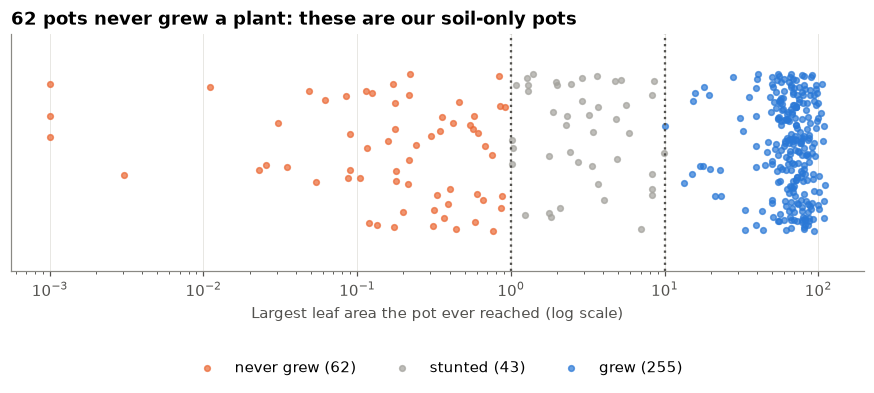

In [ ]:
# The biggest leaf area each pot reached in any photo over the whole month.
max_area = photos.groupby("plant_id").leaf_area.max()

# Sort the pots into the three groups from the table above.
status = (pd.cut(max_area, [-np.inf, 1, 10, np.inf], labels=["never grew", "stunted", "grew"])
          .astype(str).rename("status"))
print(status.value_counts().loc[["never grew", "stunted", "grew"]].to_string())

# Chart: one dot per pot, placed by its largest leaf area.
# Dots are spread up and down at random only so they don't sit on top of each other.
fig, ax = plt.subplots(figsize=(10, 2.8))
rng = np.random.default_rng(0)
for k in ["never grew", "stunted", "grew"]:
    v = max_area[status == k].clip(lower=1e-3)       # pots with exactly 0 are shown at 0.001
    ax.scatter(v, rng.uniform(-0.3, 0.3, len(v)), s=14, color=STATUS_COLORS[k], alpha=0.7, label=f"{k} ({len(v)})")
ax.set_xscale("log"); ax.set_yticks([]); ax.set_ylim(-0.45, 0.45); ax.grid(axis="y", visible=False)
ax.axvline(1, color=MUTED, ls=":"); ax.axvline(10, color=MUTED, ls=":")
ax.set_xlabel("Largest leaf area the pot ever reached (log scale)")
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.32))
ax.set_title("62 pots never grew a plant: these are our soil-only pots")
plt.show()

The scale is a "log scale": every step to the right is ten times bigger than the one before, so tiny and large values fit on one line. The pots on the far left (at 0.001) never had a plant found in any photo.

Here is what this looks like in a real photo: one tray of six pots on the afternoon of Apr 29, with empty pots next to grown plants.

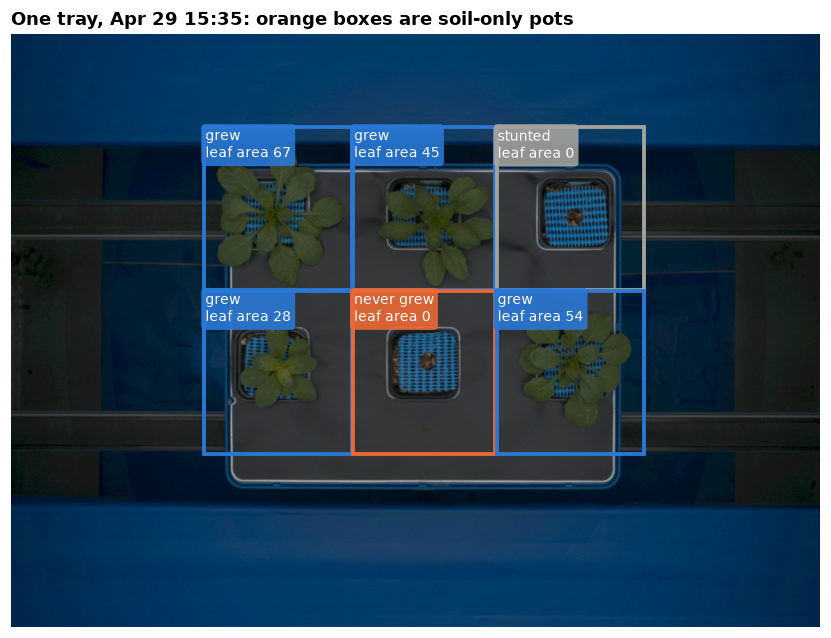

In [ ]:
# Find a tray photo from the afternoon of Apr 29 that shows both an empty pot and a grown plant.
day_photos = photos[(photos.day == "2026-04-29") & (photos.datetime.dt.hour.between(12, 18))].join(status, on="plant_id")
groups_in_photo = day_photos.groupby("thumbnail_path").status.agg(set)
pick = next(path for path, groups in groups_in_photo.items() if {"never grew", "grew"} <= groups)
tray = day_photos[day_photos.thumbnail_path == pick]

img = Image.open(DATA / "rgb2" / "rgb2-images" / "rgb2-images" / Path(pick).name)
# The pot boxes are given in pixels of the full-size photo; the saved file is a smaller copy, so we scale them.
scale = img.width / tray.image_width_px.iloc[0]

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(img); ax.axis("off")
for r in tray.itertuples():
    # Draw a coloured box around each pot, with its group and leaf area written in the corner.
    x0, x1 = r.tray_roi_crop_col_start_px * scale, r.tray_roi_crop_col_stop_px * scale
    y0, y1 = r.tray_roi_crop_row_start_px * scale, r.tray_roi_crop_row_stop_px * scale
    c = STATUS_COLORS[r.status]
    ax.add_patch(plt.Rectangle((x0 + 4, y0 + 4), x1 - x0 - 8, y1 - y0 - 8, fill=False, edgecolor=c, lw=2.5))
    ax.text(x0 + 10, y0 + 10, f"{r.status}\nleaf area {r.leaf_area:.0f}", color="white", fontsize=9, va="top",
            bbox=dict(facecolor=c, edgecolor="none", alpha=0.9, boxstyle="round,pad=0.3"))
ax.set_title(f"One tray, {tray.datetime.iloc[0]:%b %d %H:%M}: orange boxes are soil-only pots")
plt.show()

---
# Part A · What uses the water?

## 2 · How the weigh-in gaps are built

### 2a · When were the pots weighed?

We only use **Apr 21 to 30** in Part A. In those days the machine topped up nearly every pot at every visit, so every gap starts from a known weight. Before Apr 20 the pots were not yet being watered to a target, and in May many after-watering weights are missing.

A round of weigh-ins takes 1.5 to 4 hours to get through all 360 pots, so the times spread out a little. Still, they fall into three clear groups each day.

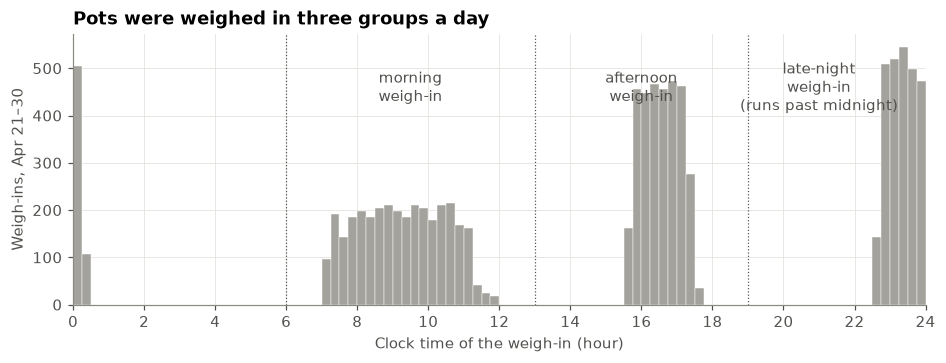

In [ ]:
# Clock time of every weigh-in between Apr 21 and Apr 30, as hours (9.5 = 09:30).
steady = w[(w.datetime >= "2026-04-21") & (w.datetime < "2026-05-01")]
clock = steady.datetime.dt.hour + steady.datetime.dt.minute / 60

# Chart: how many weigh-ins happened in each quarter of an hour of the day.
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.hist(clock, bins=np.arange(0, 24.01, 0.25), color=GREY, edgecolor="white", linewidth=0.3)
top = ax.get_ylim()[1]
for x in [6, 13, 19]:                                      # the borders between the three slots
    ax.axvline(x, color=MUTED, lw=0.8, ls=":")
for x, name in [(9.5, "morning\nweigh-in"), (16, "afternoon\nweigh-in"), (21, "late-night\nweigh-in\n(runs past midnight)")]:
    ax.text(x, top * 0.8, name, ha="center", va="center", color=MUTED)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("Clock time of the weigh-in (hour)"); ax.set_ylabel("Weigh-ins, Apr 21–30")
ax.set_title("Pots were weighed in three groups a day")
plt.show()

So every weigh-in gets a **slot** name from its clock time:

| Slot | Clock time |
|---|---|
| morning | 06:00 to 12:59 |
| afternoon | 13:00 to 18:59 |
| late night | 19:00 to 05:59 |

### 2b · One pot over one day

A **gap** is the time between one weigh-in of a pot and its next weigh-in:
- it **starts** with the weight right **after** the machine has added water;
- it **ends** with the weight at the next visit, **before** any new water goes in;
- **water lost** = start weight − end weight, and the **loss rate** = water lost ÷ hours in the gap (grams per hour).

Using the rate (grams per hour) instead of the total lets us compare gaps of different lengths fairly.

Here is one pot (plant 28773) from the morning of Apr 22 to the morning of Apr 23.

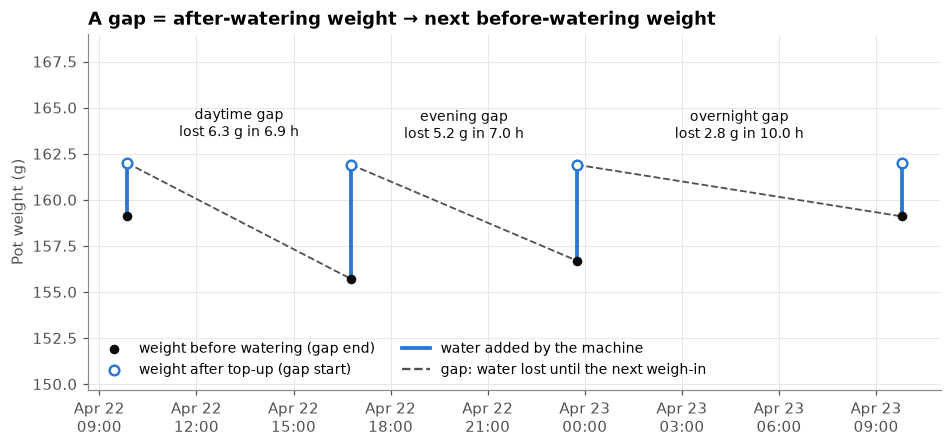

In [ ]:
# All weigh-ins of plant 28773 between Apr 22 06:00 and Apr 23 12:00.
pot = w[(w.plant_id == 28773) & (w.datetime >= "2026-04-22 06:00") & (w.datetime < "2026-04-23 12:00")]
rows = list(pot.itertuples())
slot_name = lambda h: "morning" if 6 <= h < 13 else ("afternoon" if 13 <= h < 19 else "late night")
gap_name = {("morning", "afternoon"): "daytime gap", ("afternoon", "late night"): "evening gap",
            ("late night", "morning"): "overnight gap"}

fig, ax = plt.subplots(figsize=(10, 4.2))
# Dashed lines: from the after-watering weight of one visit to the before-watering weight of the next visit.
for a, b in zip(rows[:-1], rows[1:]):
    ax.plot([a.datetime, b.datetime], [a.weight_after_watering_g, b.weight_g], color=MUTED, ls="--", lw=1.2)
    mid = a.datetime + (b.datetime - a.datetime) / 2
    hours = (b.datetime - a.datetime).total_seconds() / 3600
    name = gap_name.get((slot_name(a.datetime.hour), slot_name(b.datetime.hour)), "gap")
    ax.text(mid, a.weight_after_watering_g + 1.2, f"{name}\nlost {a.weight_after_watering_g - b.weight_g:.1f} g in {hours:.1f} h",
            ha="center", va="bottom", fontsize=9, color=INK)
# Blue bars: the water the machine added at each visit.
for r in rows:
    ax.plot([r.datetime, r.datetime], [r.weight_g, r.weight_after_watering_g], color=PLANT, lw=2.5, solid_capstyle="round")
    ax.scatter(r.datetime, r.weight_g, color=INK, s=28, zorder=3)
    ax.scatter(r.datetime, r.weight_after_watering_g, facecolor="white", edgecolor=PLANT, s=40, lw=1.6, zorder=3)
# Legend entries (empty plots, used only to label the symbols).
ax.scatter([], [], color=INK, s=28, label="weight before watering (gap end)")
ax.scatter([], [], facecolor="white", edgecolor=PLANT, s=40, lw=1.6, label="weight after top-up (gap start)")
ax.plot([], [], color=PLANT, lw=2.5, label="water added by the machine")
ax.plot([], [], color=MUTED, ls="--", label="gap: water lost until the next weigh-in")
ax.legend(loc="lower left", ncol=2, fontsize=9)
ax.set_ylim(pot.weight_g.min() - 6, pot.weight_after_watering_g.max() + 7)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
ax.set_ylabel("Pot weight (g)")
ax.set_title("A gap = after-watering weight → next before-watering weight")
plt.show()

### 2c · Build every gap

The same rule is applied to every pot. Each gap is then named after the slots it starts and ends in:

| Starts in → ends in | Gap name |
|---|---|
| morning → afternoon | **daytime** |
| afternoon → late night | **evening** |
| late night → morning | **overnight** |
| anything else (a weigh-in was skipped) | not used |

We first build the gaps for the whole month (Part B needs them too), then keep the clean ones for Part A. The bar chart counts how many gaps survive each rule.

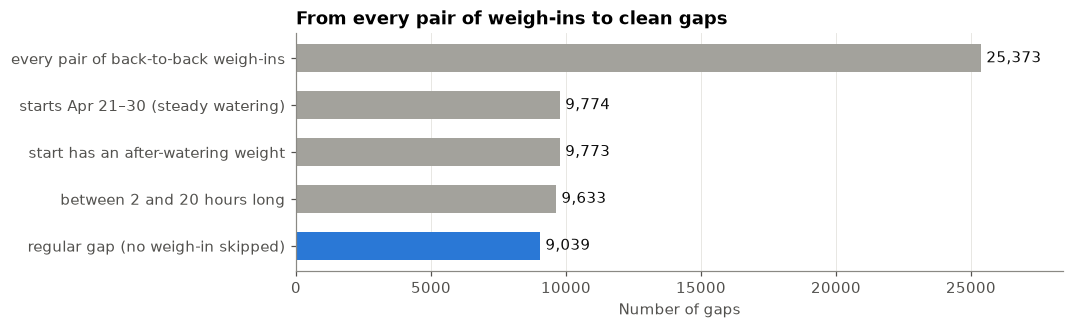

In [ ]:
def slot(hour):
    # Give every weigh-in a slot name from its clock hour (see the table in 2b).
    return np.select([(hour >= 6) & (hour < 13), (hour >= 13) & (hour < 19)], ["morning", "afternoon"], "night")


w["slot"] = slot(w.datetime.dt.hour)
next_visit = w.groupby("plant_id")      # lets us look up each pot's NEXT weigh-in with .shift(-1)

# One row per pair of back-to-back weigh-ins of the same pot.
all_gaps = pd.DataFrame({
    "plant_id": w.plant_id,
    "start": w.datetime,
    "start_slot": w.slot,
    "start_weight": w.weight_after_watering_g,    # the weight right after this visit's top-up
    "end": next_visit.datetime.shift(-1),
    "end_slot": next_visit.slot.shift(-1),
    "end_weight": next_visit.weight_g.shift(-1),  # the weight at the next visit, before new water
}).dropna(subset=["end"])                         # a pot's very last weigh-in has no next one

all_gaps["hours"] = (all_gaps.end - all_gaps.start).dt.total_seconds() / 3600
all_gaps["loss_g"] = all_gaps.start_weight - all_gaps.end_weight
all_gaps["rate"] = all_gaps.loss_g / all_gaps.hours           # grams lost per hour
# Name the gap from its start and end slots. Any other pair (a skipped visit) gets no name.
all_gaps["gap"] = (all_gaps.start_slot + "->" + all_gaps.end_slot).map(
    {"morning->afternoon": "daytime", "afternoon->night": "evening", "night->morning": "overnight"})

# Keep only the clean gaps for Part A, counting how many survive each rule.
funnel = {"every pair of back-to-back weigh-ins": len(all_gaps)}
gaps = all_gaps[(all_gaps.start >= "2026-04-21") & (all_gaps.start < "2026-05-01")]
funnel["starts Apr 21–30 (steady watering)"] = len(gaps)
gaps = gaps.dropna(subset=["start_weight"])
funnel["start has an after-watering weight"] = len(gaps)
gaps = gaps[(gaps.hours >= 2) & (gaps.hours <= 20)]
funnel["between 2 and 20 hours long"] = len(gaps)
skipped = gaps[gaps.gap.isna()]
gaps = gaps[gaps.gap.notna()].copy()
funnel["regular gap (no weigh-in skipped)"] = len(gaps)

# Chart: the number of gaps left after each rule.
fig, ax = plt.subplots(figsize=(9, 2.8))
labels, counts = list(funnel)[::-1], list(funnel.values())[::-1]
ax.barh(labels, counts, color=[PLANT] + [GREY] * (len(counts) - 1), height=0.6)
for i, c in enumerate(counts):
    ax.text(c + 200, i, f"{c:,}", va="center", color=INK)
ax.set_xlim(0, max(counts) * 1.12); ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of gaps"); ax.set_title("From every pair of weigh-ins to clean gaps")
plt.show()

Most of the drop comes from keeping only Apr 21–30. Inside that window almost every gap is usable. The few that are dropped skipped a visit (for example late night straight to the afternoon), which makes them 15 to 17 hours long and mixes day and night together.

In the chart below each dot is one gap, placed by the clock time it starts (left to right) and how long it lasts (bottom to top). The clock runs from 06:00 to 06:00 the next morning, so the late-night visits are not cut in half at midnight. The three kinds of gap form three tight clusters, and the dropped gaps are the long grey ones.

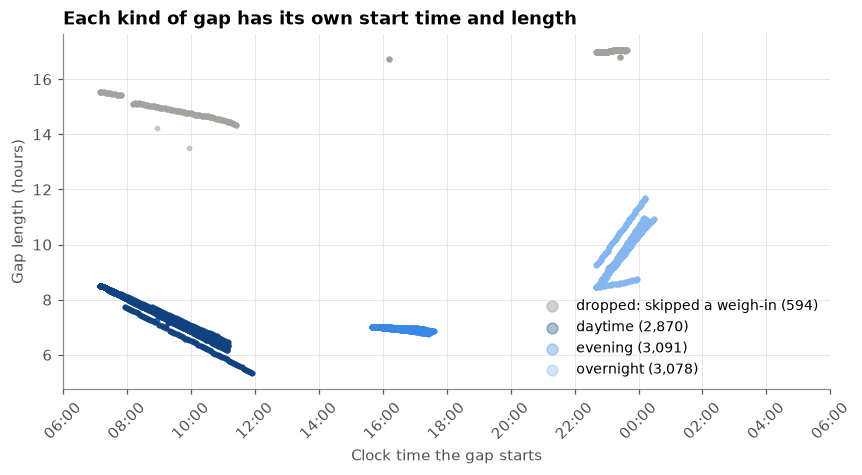

,gaps,typical_start,typical_end,median_hours,median_g_lost,median_g_per_h
gap,,,,,,
daytime,2870,07:30–11:00,16:00–17:00,7.32,6.2,0.86
evening,3091,16:00–17:00,23:00–00:00,6.96,3.7,0.53
overnight,3078,23:00–00:00,07:30–11:00,9.74,3.0,0.30


In [ ]:
def clock_from_6am(times):
    # Clock hour, with 00:00-05:59 moved to 24-30 so the late-night visits stay together.
    h = times.dt.hour + times.dt.minute / 60
    return np.where(h < 6, h + 24, h)


def clock_range(times):
    # The middle 80% of the clock times, rounded to the half hour, written as "07:30–11:00".
    fmt = lambda x: f"{int(round(x * 2) / 2) % 24:02d}:{'30' if round(x * 2) % 2 else '00'}"
    lo, hi = np.quantile(clock_from_6am(times), [0.1, 0.9])
    return f"{fmt(lo)}–{fmt(hi)}"


fig, ax = plt.subplots(figsize=(9, 4.2))
ax.scatter(clock_from_6am(skipped.start), skipped.hours, s=8, color=GREY, alpha=0.5,
           label=f"dropped: skipped a weigh-in ({len(skipped):,})")
for k in GAPS:
    s = gaps[gaps.gap == k]
    ax.scatter(clock_from_6am(s.start), s.hours, s=8, color=GAP_COLORS[k], alpha=0.35, label=f"{k} ({len(s):,})")
ax.set_xticks(range(6, 31, 2), [f"{h % 24:02d}:00" for h in range(6, 31, 2)], rotation=45)
ax.set_xlabel("Clock time the gap starts"); ax.set_ylabel("Gap length (hours)")
ax.legend(loc="lower right", markerscale=2.5, fontsize=9)
ax.set_title("Each kind of gap has its own start time and length")
plt.show()

# A summary table: how many gaps of each kind, when they typically start and end,
# and the middle (median) length, water lost and loss rate.
gap_summary = gaps.groupby("gap").agg(
    gaps=("rate", "size"),
    typical_start=("start", clock_range),
    typical_end=("end", clock_range),
    median_hours=("hours", "median"),
    median_g_lost=("loss_g", "median"),
    median_g_per_h=("rate", "median"),
).loc[GAPS]
gap_summary.round(2)

So the three gaps are:
- **daytime**: from the morning visit (about 07:30–11:00) to the afternoon visit (about 16:00–17:00), about 7 hours;
- **evening**: from the afternoon visit to the late-night visit (about 23:00–00:00), about 7 hours;
- **overnight**: from the late-night visit to the next morning visit, about 10 hours.

Pots lose water fastest in the daytime gap. But this is the **total** loss of the pot. The next sections split it into the soil's part and the plant's part.

## 3 · Soil evaporation, measured on the empty pots

The loss rate of a **never-grew** pot is pure soil evaporation. Room conditions change from day to day, so we take the typical (median) rate of the empty pots **separately for each day and each kind of gap**. We call that the **soil baseline**.

Then, for every pot with a plant, in the same kind of gap on the same day:

> **plant use = the pot's loss rate − the soil baseline**

We also attach the pot's leaf area on the day of each gap, so we can relate water use to plant size later.

Day + gap combinations with no gaps (fewer weigh-in rounds that day): Apr 25 daytime, Apr 30 daytime, Apr 30 evening


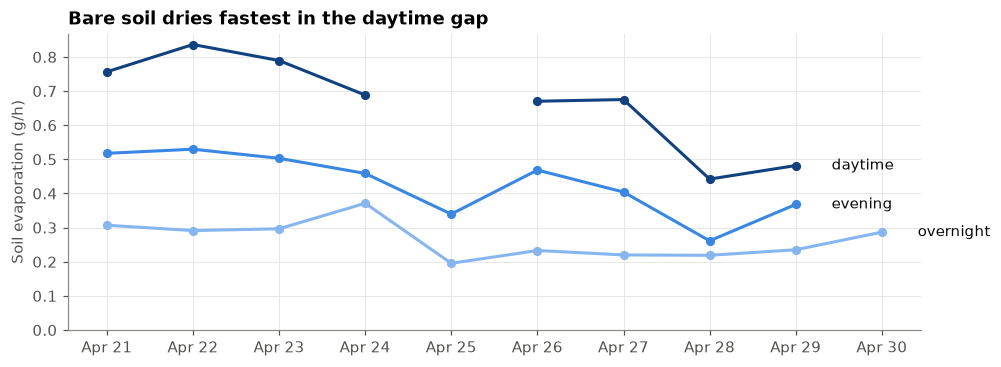

In [ ]:
gaps["day"] = gaps.start.dt.normalize()

# Leaf area of the pot on the day of the gap: the middle (median) value of that day's photos.
# The median is not thrown off by one odd photo.
daily_median_area = photos.groupby(["plant_id", "day"]).leaf_area.median().rename("leaf_area")
gaps = gaps.join(daily_median_area, on=["plant_id", "day"]).join(status, on="plant_id")

# The soil baseline: for each day and each kind of gap, the median loss rate of the empty pots.
soil = gaps[gaps.status == "never grew"].groupby(["day", "gap"]).rate.median().rename("soil_rate")
gaps = gaps.join(soil, on=["day", "gap"])

# Plant use = what the pot lost, minus what bare soil lost in the same gap on the same day.
gaps["plant_rate"] = gaps.rate - gaps.soil_rate
gaps = gaps[gaps.soil_rate.notna()]          # drop gaps with no empty-pot baseline that day

# Which day + gap combinations have no gaps at all?
soil_by_day = soil.unstack()[GAPS].reindex(pd.date_range("2026-04-21", "2026-04-30"))
missing = [f"{d:%b %d} {k}" for d in soil_by_day.index for k in GAPS if pd.isna(soil_by_day.loc[d, k])]
print("Day + gap combinations with no gaps (fewer weigh-in rounds that day):", ", ".join(missing))

# Chart: the soil baseline day by day, one line per kind of gap.
fig, ax = plt.subplots(figsize=(10, 3.5))
for k in GAPS:
    ax.plot(soil_by_day.index, soil_by_day[k], marker="o", ms=5, lw=2, color=GAP_COLORS[k])
    last = soil_by_day[k].dropna()
    ax.text(last.index[-1] + pd.Timedelta(hours=10), last.iloc[-1], k, va="center", color=INK)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylabel("Soil evaporation (g/h)"); ax.set_ylim(0, None)
ax.set_title("Bare soil dries fastest in the daytime gap")
plt.show()

Even with **no plant at all**, soil loses water about 2 to 3 times faster in the daytime gap than overnight. That points to the room itself: under the growth lights the air is warmer and drier, so the soil surface dries faster.

Soil evaporation also drifts down late in the window (Apr 28–29), probably because the room conditions changed. That drift is why the baseline is taken day by day instead of as one fixed number. A few points are missing (Apr 25 daytime, Apr 30 daytime and evening) because those days had fewer weigh-in rounds.

## 4 · Soil vs plant: where the water goes

Now the main result. For the pots that **grew** a plant, we split their average loss rate into the soil's part and the plant's part.

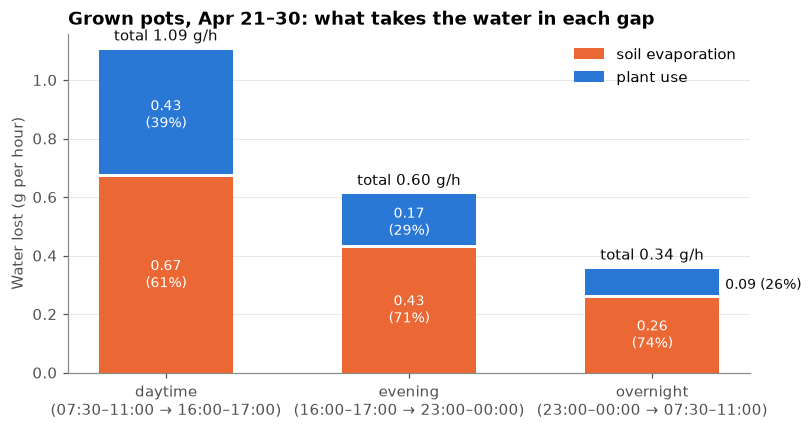

,rate,soil_rate,plant_rate
gap,,,
daytime,1.093,0.667,0.425
evening,0.599,0.426,0.172
overnight,0.344,0.255,0.089


In [ ]:
# Average loss, soil part and plant part for the grown pots, per kind of gap.
grown = gaps[gaps.status == "grew"]
split = grown.groupby("gap")[["rate", "soil_rate", "plant_rate"]].mean().loc[GAPS]

# Chart: one stacked bar per kind of gap, soil at the bottom and plant on top.
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(GAPS))
ax.bar(x, split.soil_rate, width=0.55, color=SOIL, label="soil evaporation")
ax.bar(x, split.plant_rate, width=0.55, bottom=split.soil_rate + 0.01, color=PLANT, label="plant use")
for i, k in enumerate(GAPS):
    s, p = split.loc[k, "soil_rate"], split.loc[k, "plant_rate"]
    ax.text(i, s / 2, f"{s:.2f}\n({s / (s + p):.0%})", ha="center", va="center", color="white", fontsize=9)
    if p > 0.12:
        ax.text(i, s + p / 2, f"{p:.2f}\n({p / (s + p):.0%})", ha="center", va="center", color="white", fontsize=9)
    else:  # the plant part is too thin to write inside, so write it beside the bar
        ax.text(i + 0.3, s + p / 2, f"{p:.2f} ({p / (s + p):.0%})", ha="left", va="center", color=INK, fontsize=9)
    ax.text(i, s + p + 0.03, f"total {s + p:.2f} g/h", ha="center", va="bottom", color=INK)
ax.set_xticks(x, [f"{k}\n({gap_summary.loc[k, 'typical_start']} → {gap_summary.loc[k, 'typical_end']})" for k in GAPS])
ax.set_ylabel("Water lost (g per hour)"); ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
ax.set_title("Grown pots, Apr 21–30: what takes the water in each gap")
plt.show()
split.round(3)

Averaged over the whole window, the soil takes the larger share in every gap. The plant's share is biggest in the daytime gap (39%) and smallest overnight (26%).

Rates per hour are easy to compare, but the gaps have different lengths. Below is the same split in **grams per gap**, adding up to a whole day. We compare the start of the window (Apr 21–23, small seedlings) with the end (Apr 27–29, bigger plants).

Grams lost per gap, Apr 21–23:
            soil_g  plant_g
gap                       
daytime       5.9      0.3
evening       3.6     -0.1
overnight     2.9     -0.2

Grams lost per gap, Apr 27–29:
            soil_g  plant_g
gap                       
daytime       4.0      6.2
evening       2.4      2.9
overnight     2.2      1.8


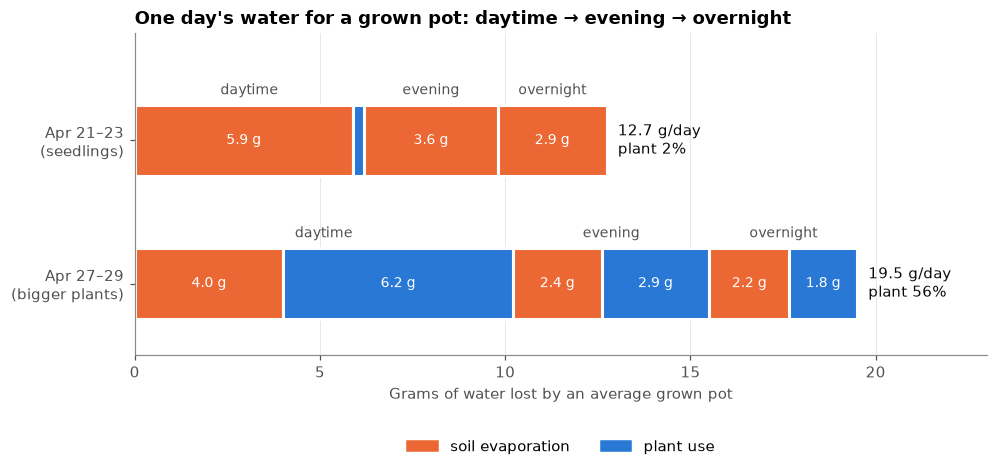

In [ ]:
# Turn rates into grams: rate × length of the gap.
grown = grown.assign(soil_g=grown.soil_rate * grown.hours, plant_g=grown.plant_rate * grown.hours)


def day_budget(days):
    # Average grams lost to soil and to plant in each kind of gap, over the given days.
    s = grown[grown.day.isin(pd.to_datetime(days))]
    return s.groupby("gap")[["soil_g", "plant_g"]].mean().loc[GAPS]


early_budget = day_budget(["2026-04-21", "2026-04-22", "2026-04-23"])
late_budget = day_budget(["2026-04-27", "2026-04-28", "2026-04-29"])
print("Grams lost per gap, Apr 21–23:\n", early_budget.round(1).to_string())
print("\nGrams lost per gap, Apr 27–29:\n", late_budget.round(1).to_string())

# The seedlings' plant use is about 0; the small negative numbers are just noise around 0,
# so in the chart we draw them as 0.
early_budget, late_budget = early_budget.clip(lower=0), late_budget.clip(lower=0)

# Chart: one bar per period, split into daytime → evening → overnight, each split into soil and plant.
fig, ax = plt.subplots(figsize=(10, 3.8))
for row, budget in enumerate([late_budget, early_budget]):
    left = 0
    for k in GAPS:
        start = left
        for part, color in [("soil_g", SOIL), ("plant_g", PLANT)]:
            v = budget.loc[k, part]
            ax.barh(row, v, left=left, color=color, height=0.5, edgecolor="white", linewidth=2)
            if v > 1.2:
                ax.text(left + v / 2, row, f"{v:.1f} g", ha="center", va="center", color="white", fontsize=9)
            left += v
        ax.text((start + left) / 2, row + 0.3, k, ha="center", va="bottom", fontsize=9, color=MUTED)
    total = budget.values.sum()
    ax.text(left + 0.3, row, f"{total:.1f} g/day\nplant {budget.plant_g.sum() / total:.0%}", va="center", color=INK)
ax.set_yticks([0, 1], ["Apr 27–29\n(bigger plants)", "Apr 21–23\n(seedlings)"])
ax.set_ylim(-0.5, 1.75)
ax.legend(handles=[Patch(color=SOIL, label="soil evaporation"), Patch(color=PLANT, label="plant use")],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_xlabel("Grams of water lost by an average grown pot"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, late_budget.values.sum() * 1.18)
ax.set_title("One day's water for a grown pot: daytime → evening → overnight")
plt.show()

The picture flips within a week. On Apr 21–23 almost all of a grown pot's 12.7 g a day is the soil drying out: the seedlings are too small to matter. By Apr 27–29 the pot loses 19.5 g a day, the plant takes 56% of it, and in the daytime gap the plant (6.2 g) takes more than the soil (4.0 g).

Here is the same thing day by day, one bar per day. The orange part (soil) stays level or falls a little, while the blue part (plant) grows as the leaves grow. Empty spaces are days with no gap of that kind.

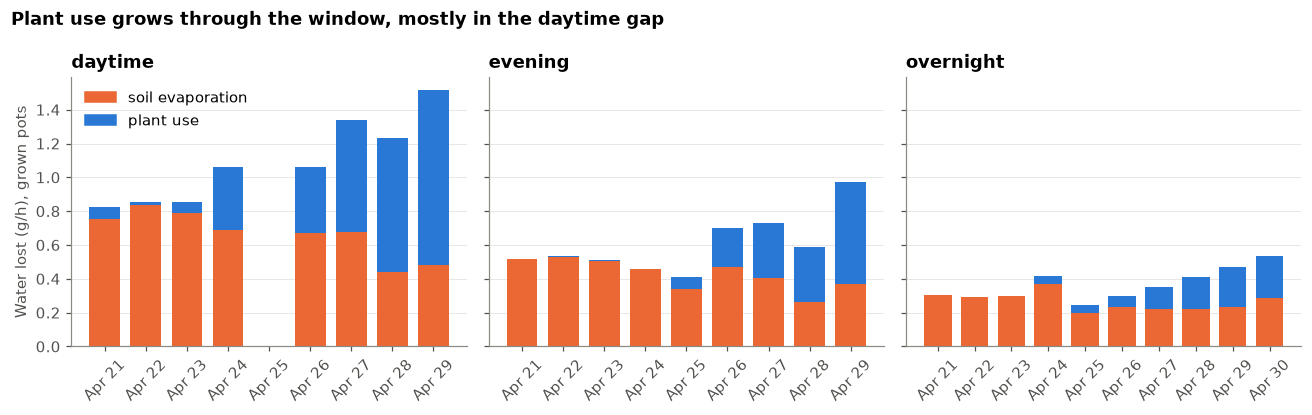

In [ ]:
# Average soil and plant rate for grown pots, per kind of gap and per day.
by_day = grown.groupby(["gap", "day"])[["soil_rate", "plant_rate"]].mean()
window = pd.date_range("2026-04-21", "2026-04-30")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, k in zip(axes, GAPS):
    d = by_day.loc[k].reindex(window)
    ax.bar(d.index, d.soil_rate, width=0.75, color=SOIL)
    ax.bar(d.index, d.plant_rate.clip(lower=0), bottom=d.soil_rate, width=0.75, color=PLANT)
    ax.set_title(k); ax.grid(axis="x", visible=False)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Water lost (g/h), grown pots")
axes[0].legend(handles=[Patch(color=SOIL, label="soil evaporation"), Patch(color=PLANT, label="plant use")], loc="upper left")
fig.suptitle("Plant use grows through the window, mostly in the daytime gap", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 5 · Check: is "pot minus empty pot" a fair way to measure plant use?

If the subtraction is fair, two things should be true:
1. a pot whose plant is tiny should show plant use **close to 0**;
2. plant use should **rise with leaf area**.

To check, we sort every gap of every planted pot (stunted and grown) into groups by the pot's leaf area that day, and plot the typical plant use in each group.

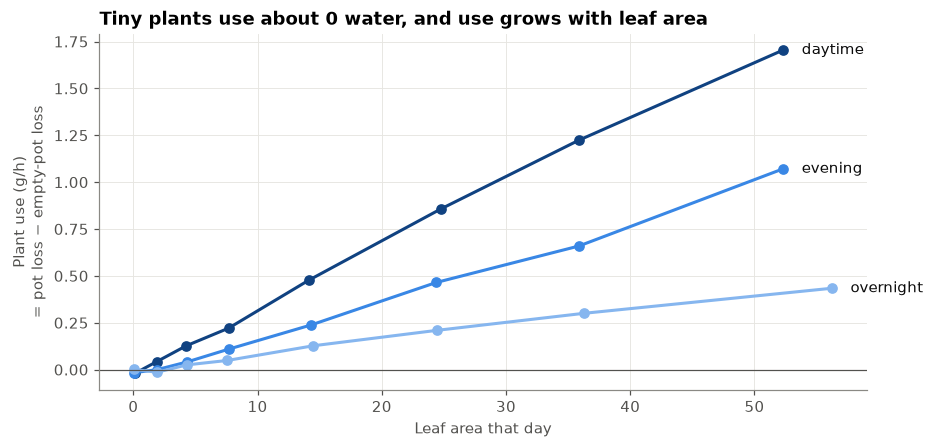

In [ ]:
# Every gap of a pot that had a plant (stunted or grown).
planted = gaps[gaps.status != "never grew"]

# Sort the gaps into groups by leaf area that day, then take the median plant use in each group.
area_groups = [0, 1, 3, 6, 10, 20, 30, 45, 120]
planted = planted.assign(area_group=pd.cut(planted.leaf_area, area_groups, include_lowest=True))
curve = planted.groupby(["gap", "area_group"], observed=True).agg(
    area=("leaf_area", "median"), plant=("plant_rate", "median"), n=("rate", "size"))
curve = curve[curve.n >= 30]          # only groups with at least 30 gaps, so each point is reliable

fig, ax = plt.subplots(figsize=(9, 4.2))
for k in GAPS:
    c = curve.loc[k]
    ax.plot(c.area, c.plant, marker="o", ms=6, lw=2, color=GAP_COLORS[k])
    ax.text(c.area.iloc[-1] + 1.5, c.plant.iloc[-1], k, va="center", color=INK)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel("Leaf area that day"); ax.set_ylabel("Plant use (g/h)\n= pot loss − empty-pot loss")
ax.set_title("Tiny plants use about 0 water, and use grows with leaf area")
plt.show()

Both checks pass: plant use starts near 0 for the smallest plants and climbs with leaf area. The daytime line climbs far more steeply than the overnight line.

## 6 · Why does the plant use so much more water in the daytime?

A big plant uses more water than a small one, so to compare fairly we divide plant use by leaf area: **water used per piece of leaf, per hour**. That shows how hard each piece of leaf is working, whatever the size of the plant. We only use grown pots with a leaf area of at least 5 that day, so we never divide by a tiny number.

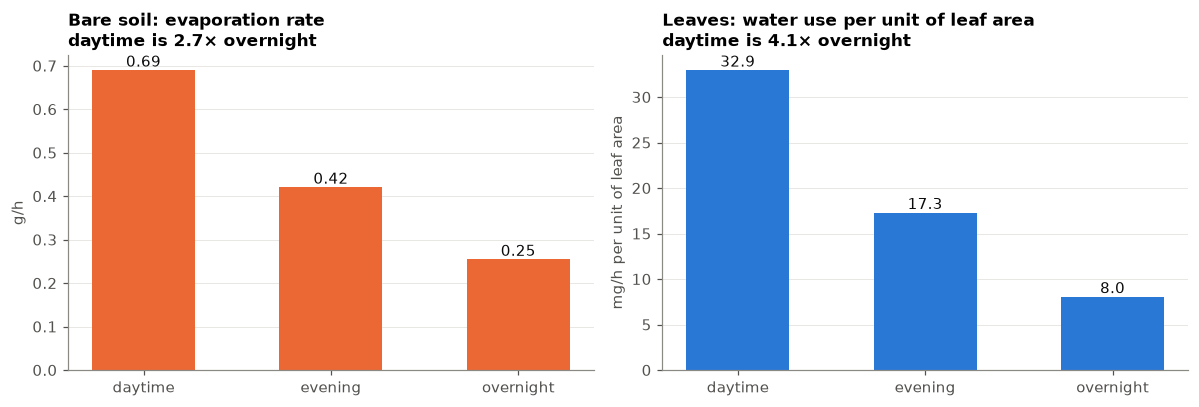

In [ ]:
# Plant use per unit of leaf area, for grown pots with at least 5 units of leaf that day.
big = grown[grown.leaf_area >= 5]
per_leaf = big.groupby("gap").apply(lambda s: (s.plant_rate / s.leaf_area).median()).loc[GAPS]

# For comparison: how fast bare soil dries in each kind of gap.
soil_typical = gaps[gaps.status == "never grew"].groupby("gap").rate.median().loc[GAPS]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, vals, color, title, unit in [
    (axes[0], soil_typical, SOIL, "Bare soil: evaporation rate", "g/h"),
    (axes[1], per_leaf * 1000, PLANT, "Leaves: water use per unit of leaf area", "mg/h per unit of leaf area"),
]:
    ax.bar(GAPS, vals, color=color, width=0.55)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.2f}" if unit == "g/h" else f"{v:.1f}", ha="center", va="bottom", color=INK)
    ratio = vals["daytime"] / vals["overnight"]
    ax.set_title(f"{title}\ndaytime is {ratio:.1f}× overnight", fontsize=11)
    ax.set_ylabel(unit); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Two different things cause the daytime peak:
- **The soil** dries 2.7 times faster by day than overnight. Nothing living is involved, so this is the room: warmer, drier air under the lights.
- **The leaves** use 4.1 times more water per piece of leaf by day than overnight, a bigger jump than the soil's. Leaves lose water through tiny pores that open in the light (so the plant can take in CO₂ for photosynthesis) and close in the dark.

So the plant's share of the loss is highest in the daytime gap and lowest overnight. The evening gap sits in between: it starts in the afternoon with the lights on, and probably ends after lights-out.

## 7 · Does the metal change soil drying or water use per leaf?

This matters for two reasons. If the metal changed how fast soil dries, our soil baseline could be off, because most empty pots are at high metal levels. And if the metal changed water use per leaf, that would be a direct effect of the metal on how leaves work.

**A warning before comparing.** The metal levels are not evenly filled, because the metal decides which pots grow:
- **Empty pots** are mostly at **high** metal (500 and 1000). Only a handful are at low metal.
- **Grown plants** are fewer, and smaller, at **high** metal.

So each comparison below has small groups somewhere, and we have to check that plant size isn't doing the work.

To compare, each pot gets **one number** (its median over the window), so pots with many gaps don't count more. Chart titles show a **p-value** from a standard test of whether the groups differ (the Kruskal–Wallis test). A p-value above 0.05 means no clear difference. With small groups, "no clear difference" rules out a large effect, not a small one.

### 7a · Soil evaporation of the empty pots

Empty pots per metal level: 0: 8, 50: 5, 100: 8, 200: 2, 500: 18, 1000: 21
Metal 0–200: 23 empty pots, median 0.67 g/h
Metal 500–1000: 39 empty pots, median 0.74 g/h


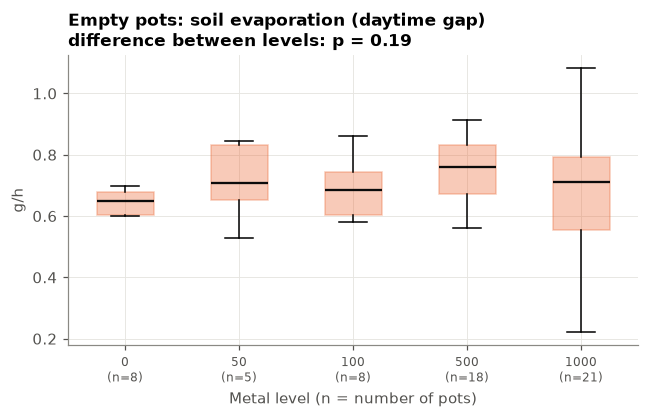

In [ ]:
# Add each pot's metal level to its gaps.
gaps = gaps.join(design.metal, on="plant_id")


def metal_boxes(ax, data, col, color, title, ylab):
    # One box per metal level (levels with fewer than 3 pots are left out),
    # and a p-value for "do the levels differ?" in the title.
    by_level = [data[data.metal == m][col].values for m in metal_levels]
    keep = [i for i, v in enumerate(by_level) if len(v) >= 3]
    box = ax.boxplot([by_level[i] for i in keep], positions=range(len(keep)), widths=0.5, showfliers=False,
                     patch_artist=True, medianprops=dict(color=INK, lw=1.5))
    for patch in box["boxes"]:
        patch.set(facecolor=color, alpha=0.35, edgecolor=color)
    p = kruskal(*[by_level[i] for i in keep]).pvalue
    ax.set_xticks(range(len(keep)), [f"{metal_levels[i]}\n(n={len(by_level[i])})" for i in keep], fontsize=8)
    ax.set_xlabel("Metal level (n = number of pots)"); ax.set_ylabel(ylab)
    ax.set_title(f"{title}\ndifference between levels: p = {p:.2f}", fontsize=11)


# Empty pots: each pot's median soil evaporation in the daytime gap.
empty_pots = (gaps[(gaps.status == "never grew") & (gaps.gap == "daytime")]
              .groupby(["plant_id", "metal"]).rate.median().reset_index())
counts = empty_pots.groupby("metal").size()
print("Empty pots per metal level:", ", ".join(f"{m}: {n}" for m, n in counts.items()))
low, high = empty_pots[empty_pots.metal <= 200].rate, empty_pots[empty_pots.metal >= 500].rate
print(f"Metal 0–200: {len(low)} empty pots, median {low.median():.2f} g/h")
print(f"Metal 500–1000: {len(high)} empty pots, median {high.median():.2f} g/h")

fig, ax = plt.subplots(figsize=(6, 3.9))
metal_boxes(ax, empty_pots, "rate", SOIL, "Empty pots: soil evaporation (daytime gap)", "g/h")
plt.tight_layout(); plt.show()

No clear difference between the levels. Level 200 has only 2 empty pots, so it isn't shown. But notice how uneven the groups are: 23 empty pots at metal 0–200 against 39 at 500–1000. The high-metal empty pots dry a little faster on average (0.74 against 0.67 g/h). That gap isn't statistically clear, but because the soil baseline is built mostly from high-metal pots, we test it directly in 7c.

### 7b · Water use per piece of leaf, comparing plants of the same size

Dividing plant use by leaf area is meant to remove plant size. But the plants that survive high metal are **smaller**, and if small plants use water differently per piece of leaf, the comparison is still unfair. So we check that first.

Water use per leaf vs plant size: rank correlation 0.19 (p = 0.004)
Metal effect after allowing for plant size: p = 0.81


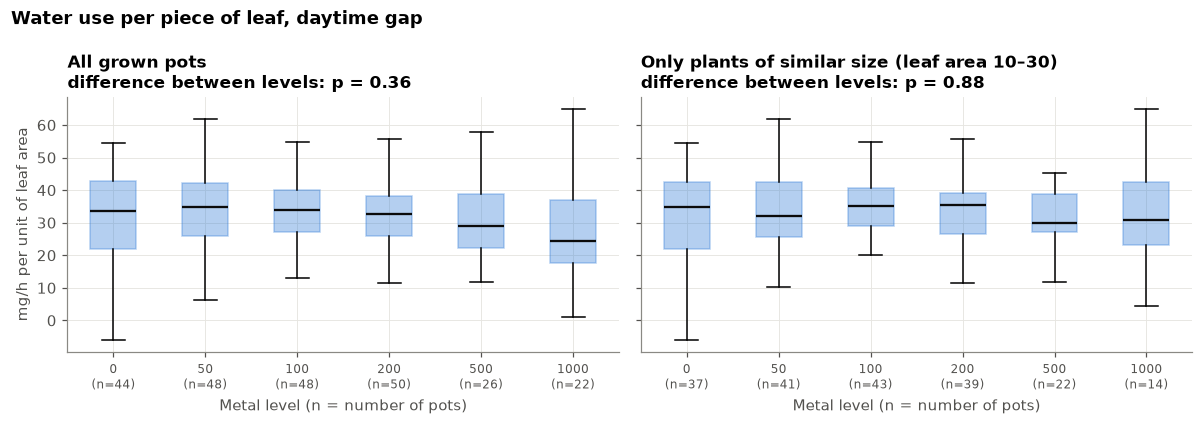

,grown pots,typical leaf size,water per leaf (all),pots of size 10–30,water per leaf (size 10–30)
metal,,,,,
0,44,17.8,33.7,37,34.8
50,48,19.5,34.7,41,32.1
100,48,18.9,33.8,43,35.2
200,50,16.3,32.5,39,35.5
500,26,16.2,28.9,22,29.9
1000,22,12.0,24.4,14,30.8


In [ ]:
# Grown pots: plant use per unit of leaf area in the daytime gap (one number per pot, its median),
# and the pot's typical leaf area in those same gaps.
leaf_rows = gaps[(gaps.status == "grew") & (gaps.gap == "daytime") & (gaps.leaf_area >= 5)]
leaf_pots = (leaf_rows.assign(per_leaf=leaf_rows.plant_rate / leaf_rows.leaf_area * 1000)
             .groupby(["plant_id", "metal"])
             .agg(per_leaf=("per_leaf", "median"), leaf_size=("leaf_area", "median")).reset_index())

# Does water use per piece of leaf depend on plant size?
rho, p_size = spearmanr(leaf_pots.leaf_size, leaf_pots.per_leaf)
print(f"Water use per leaf vs plant size: rank correlation {rho:.2f} (p = {p_size:.3f})")

# Plants of a similar size only: typical leaf area between 10 and 30.
like_sized = leaf_pots[leaf_pots.leaf_size.between(10, 30)]

# A fairer test: does adding the metal level improve a fit of "water per leaf from plant size"?
# If not, the metal has no clear effect once plant size is taken into account.
with_metal = smf.ols("per_leaf ~ np.log(leaf_size) + C(metal)", data=leaf_pots).fit()
without_metal = smf.ols("per_leaf ~ np.log(leaf_size)", data=leaf_pots).fit()
p_size_adjusted = with_metal.compare_f_test(without_metal)[1]
print(f"Metal effect after allowing for plant size: p = {p_size_adjusted:.2f}")

by_metal = leaf_pots.groupby("metal")
summary_7b = pd.DataFrame({
    "grown pots": by_metal.size(),
    "typical leaf size": by_metal.leaf_size.median(),
    "water per leaf (all)": by_metal.per_leaf.median(),
    "pots of size 10–30": like_sized.groupby("metal").size(),
    "water per leaf (size 10–30)": like_sized.groupby("metal").per_leaf.median(),
})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
metal_boxes(axes[0], leaf_pots, "per_leaf", PLANT, "All grown pots", "mg/h per unit of leaf area")
metal_boxes(axes[1], like_sized, "per_leaf", PLANT, "Only plants of similar size (leaf area 10–30)", "")
fig.suptitle("Water use per piece of leaf, daytime gap", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
summary_7b.round(1)

- Looking at all grown pots, water use per piece of leaf seems to **fall** at high metal, from about 34 at metal 0 to about 24 at 1000.
- But the plants at 1000 are the smallest, and **smaller plants use less water per piece of leaf whatever the metal** (a clear link). So part of that fall is just plant size.
- Comparing **plants of a similar size** (right chart), the levels look alike (p = 0.88), and the size-aware test also finds no clear metal effect (p = 0.81).

So: **no clear effect of metal on water use per piece of leaf once plant size is allowed for.** With only 22–26 grown plants at the high levels, this rules out a large effect but not a small one. Mainly, the metal changes water use by changing **how much leaf there is**, and whether a plant grows at all.

### 7c · Does the soil baseline depend on which empty pots we use?

The baseline is built from all 62 empty pots, and 39 of them are at high metal. Here we rebuild it three ways (all empty pots, only low-metal ones, only high-metal ones) and split the grown pots' loss again each time. If the results barely move, the baseline is safe.

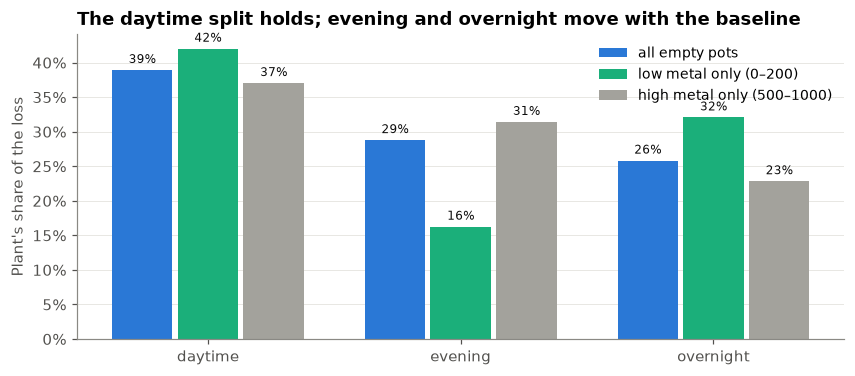

,empty pots used,fewest on one day,"plant share, daytime","plant share, evening","plant share, overnight","plant share of the day, Apr 27–29"
all empty pots,62,21,39%,29%,26%,56%
low metal only (0–200),23,7,42%,16%,32%,56%
high metal only (500–1000),39,14,37%,31%,23%,56%


In [ ]:
def split_with_baseline(use_pot):
    # Rebuild the soil baseline from a chosen set of empty pots (median per day and kind of gap),
    # then split the grown pots' loss into soil and plant, as in section 4.
    empties = gaps[(gaps.status == "never grew") & use_pot(gaps.metal)]
    soil_here = empties.groupby(["day", "gap"]).rate.median().rename("soil_here")
    g = gaps[gaps.status == "grew"].join(soil_here, on=["day", "gap"]).dropna(subset=["soil_here"])
    by_gap = g.groupby("gap").agg(total=("rate", "mean"), soil=("soil_here", "mean")).loc[GAPS]
    share = (by_gap.total - by_gap.soil) / by_gap.total
    # The plant's share of a whole day's loss on Apr 27–29 (as in the day-budget chart of section 4).
    late = g[g.day.isin(pd.to_datetime(["2026-04-27", "2026-04-28", "2026-04-29"]))]
    late = late.assign(soil_g=late.soil_here * late.hours, plant_g=(late.rate - late.soil_here) * late.hours)
    budget = late.groupby("gap")[["soil_g", "plant_g"]].mean().loc[GAPS].clip(lower=0)
    return {
        "empty pots used": empties.plant_id.nunique(),
        "fewest on one day": empties.groupby(["day", "gap"]).plant_id.nunique().min(),
        **{f"plant share, {k}": share[k] for k in GAPS},
        "plant share of the day, Apr 27–29": budget.plant_g.sum() / budget.values.sum(),
    }


baselines = {
    "all empty pots": lambda m: m >= 0,
    "low metal only (0–200)": lambda m: m <= 200,
    "high metal only (500–1000)": lambda m: m >= 500,
}
check = pd.DataFrame({name: split_with_baseline(use_pot) for name, use_pot in baselines.items()}).T

# Chart: the plant's share of the loss in each kind of gap, for each way of building the baseline.
fig, ax = plt.subplots(figsize=(9, 3.6))
width = 0.26
for j, (name, color) in enumerate(zip(check.index, [PLANT, AQUA, GREY])):
    vals = [check.loc[name, f"plant share, {k}"] for k in GAPS]
    ax.bar(np.arange(3) + (j - 1) * width, vals, width=width * 0.92, color=color, label=name)
    for i, v in enumerate(vals):
        ax.text(i + (j - 1) * width, v + 0.01, f"{v:.0%}", ha="center", fontsize=8, color=INK)
ax.set_xticks(range(3), GAPS); ax.set_ylabel("Plant's share of the loss")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper right", fontsize=9); ax.grid(axis="x", visible=False)
ax.set_title("The daytime split holds; evening and overnight move with the baseline")
plt.show()

check_show = check.copy()
check_show[["empty pots used", "fewest on one day"]] = check_show[["empty pots used", "fewest on one day"]].astype(int)
for c in check_show.columns:
    if c.startswith("plant share"):
        check_show[c] = (check_show[c] * 100).round(0).astype(int).astype(str) + "%"
check_show

- **Daytime** barely moves: the plant takes about 37–42% of the loss whichever empty pots set the baseline.
- **The whole day late in the window** doesn't move either: about 56% plant either way.
- **Evening and overnight do move**: with only low-metal empty pots the evening plant share drops to about 16% and the overnight share rises to about 32%. The low-metal group is small (as few as 7 empty pots on some days), so it is noisy.

So the main findings are safe: the plant's share grows from almost nothing to over half within a week, and it is biggest in the daytime gap. **The exact evening and overnight split is uncertain**; treat those numbers as rough.

### Part A in one table

Baseline from all 62 empty pots. The evening and overnight shares are rough (see 7c).

| Gap | Total loss | Soil evaporation | Plant use |
|---|---|---|---|
| daytime | 1.09 g/h | 0.67 g/h (61%) | 0.43 g/h (39%) |
| evening | 0.60 g/h | 0.43 g/h (71%) | 0.17 g/h (29%) |
| overnight | 0.34 g/h | 0.26 g/h (74%) | 0.09 g/h (26%) |

These are averages for grown pots over Apr 21–30. The plant's share grows quickly, from about 2% of the daily loss on Apr 21–23 to 56% on Apr 27–29.

---
# Part B · How big will each plant get?

## 8 · The task, in pictures

**What we predict:** each plant's average leaf area on May 6 and 7, the last two days of the experiment.

**What the model may use:** only data from **before Apr 26 00:00**, that is, up to the end of Apr 25. That is 11 to 12 days before the end. Anything later would let the model peek at the answer.

**How we build it:** start with the least information and add one group at a time, measuring how much each one helps.

| Step | What we add |
|---|---|
| 0 | nothing: guess the average size for every plant |
| 1 | water loss |
| 2 | water gain (the top-ups) |
| 3 | a straight-line growth trend for each plant |
| 4 | an S-shaped growth curve for each plant |
| 5 | the plant's size history |
| 6 | metal level and genotype |
| 7 | leaf shape and colour |
| 8 | try different kinds of model |
| 9 | remove what no longer helps |


360 plants to predict. Final leaf area: median 53.7, largest 106.8
status
never grew     62
stunted        43
grew          255


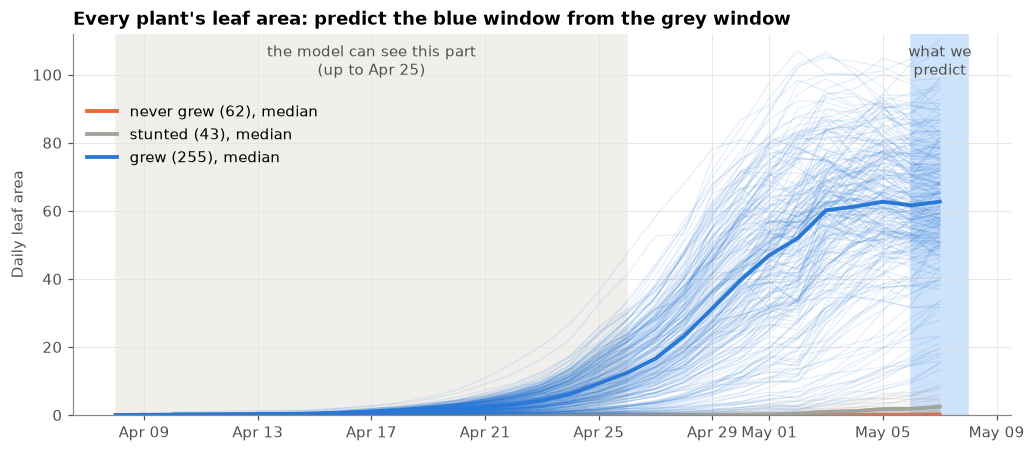

In [ ]:
CUTOFF = pd.Timestamp("2026-04-26")                 # inputs must come from before this moment (= up to end of Apr 25)
TARGET_DAYS = pd.to_datetime(["2026-05-06", "2026-05-07"])

# The answer we want to predict: each plant's average leaf area over May 6 and 7.
target = daily[daily.day.isin(TARGET_DAYS)].groupby("plant_id").leaf_area.mean().rename("final_leaf_area")
plants = design.index.intersection(target.index)   # the plants we predict (all 360)
y = target.loc[plants].values                       # their final sizes, in the same order as `plants`

# The group labels from section 1c, lined up with `plants`. Only used for colours and reporting.
plant_status = status.loc[plants]
grew = (plant_status == "grew").values
print(f"{len(plants)} plants to predict. Final leaf area: median {np.median(y):.1f}, largest {y.max():.1f}")
print(plant_status.value_counts().loc[["never grew", "stunted", "grew"]].to_string())

# Chart: every plant's daily leaf area over the month (thin lines), with the median of each group (thick lines).
wide = daily.pivot(index="plant_id", columns="day", values="leaf_area").loc[plants]
fig, ax = plt.subplots(figsize=(11, 4.5))
for k in ["never grew", "stunted", "grew"]:
    rows = wide[plant_status.values == k]
    for _, r in rows.iterrows():
        ax.plot(r.index, r.values, color=STATUS_COLORS[k], alpha=0.12, lw=0.8)
    ax.plot(rows.columns, rows.median(), color=STATUS_COLORS[k], lw=2.5, label=f"{k} ({len(rows)}), median")
ax.axvspan(DAY0, CUTOFF, color="#f0efec", zorder=0)                                        # what the model can see
ax.axvspan(TARGET_DAYS[0], TARGET_DAYS[1] + pd.Timedelta(days=1), color="#cde2fb", zorder=0)  # what it predicts
ax.text(DAY0 + pd.Timedelta(days=9), 100, "the model can see this part\n(up to Apr 25)", ha="center", color=MUTED)
ax.text(TARGET_DAYS[0] + pd.Timedelta(hours=24), 100, "what we\npredict", ha="center", color=MUTED)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylabel("Daily leaf area"); ax.set_ylim(0, 112)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.85))
ax.set_title("Every plant's leaf area: predict the blue window from the grey window")
plt.show()

## 9 · How we score each step

The fair test is to score a model only on plants it **did not learn from**. So we:
1. split the 360 plants into 5 groups at random;
2. teach the model on 4 groups and let it predict the 5th;
3. rotate until every plant has been predicted once;
4. repeat all of that with 3 different random splits, and average.

(This is called **5-fold cross-validation**.)

We report three numbers:
- **Average miss (MAE)**: on average, how far the prediction is from the real final size, in leaf-area units. Lower is better. For scale, final sizes run from 0 to about 107.
- **R²**: how much of the difference between plants the model explains. 0 means no better than guessing the average; 1 means perfect.
- **Average miss on plants that grew**: the same as the first, but only for the 255 plants that grew. This is the hard part. Failed pots are easy (predict about 0), and they make the overall number look better than it is.

At each step we try two kinds of model:
- **Linear regression** finds the best way to add up the inputs, each with its own weight. It is simple and easy to read, but it can only add things up; it can't learn bends or cut-offs on its own. We use the "ridge" version, which adds a small penalty so it stays steady when there are many inputs.
- **Random forest** builds 500 small decision trees (rules like "if the plant was bigger than 8 on Apr 25 and growing faster than 1 a day, then…") and averages them. It can learn bends and cut-offs.

Some inputs are blank for some plants (for example, there is no growth curve for a plant that hasn't come up yet). Blanks are filled with the typical value of that input, and an extra yes/no column tells the model that the value was blank.

In [ ]:
def score(X, model, repeats=3, cv=None, groups=None):
    # Predict every plant with a model that never saw it (see the steps above),
    # repeat with different random splits, and return the scores plus the average prediction per plant.
    predictions = []
    for seed in range(repeats):
        folds = cv or KFold(5, shuffle=True, random_state=seed)      # 5 random groups of plants
        p = cross_val_predict(model, X, y, cv=folds, groups=groups)
        predictions.append(np.clip(p, 0, None))                     # leaf area can't be negative
    return {
        "MAE": np.mean([mean_absolute_error(y, p) for p in predictions]),
        "R2": np.mean([r2_score(y, p) for p in predictions]),
        "MAE grew": np.mean([mean_absolute_error(y[grew], p[grew]) for p in predictions]),
    }, np.mean(predictions, axis=0)


# Fill blanks with the typical (median) value, and add a yes/no column saying "this was blank".
fill_blanks = lambda: SimpleImputer(strategy="median", add_indicator=True)

# Linear regression: fill blanks, put every input on the same scale, then fit.
# It tries 20 penalty sizes and keeps the one that works best.
linear = make_pipeline(fill_blanks(), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))

# Random forest: fill blanks, then 500 decision trees, each leaf holding at least 2 plants.
forest = make_pipeline(fill_blanks(), RandomForestRegressor(n_estimators=500, min_samples_leaf=2, n_jobs=-1, random_state=0))

ladder = []      # one row per step, so we can chart all the steps together at the end


def step(name, X):
    # Score both models on the inputs so far, remember the result, and print a one-line summary.
    lin, _ = score(X, linear)
    rf, rf_pred = score(X, forest)
    ladder.append({"step": name, "inputs": X.shape[1], "linear MAE": lin["MAE"], "forest MAE": rf["MAE"],
                   "forest R2": rf["R2"], "linear MAE (grew)": lin["MAE grew"], "forest MAE (grew)": rf["MAE grew"]})
    print(f"{name}: {X.shape[1]} inputs | linear: average miss {lin['MAE']:.2f} | forest: average miss {rf['MAE']:.2f}, "
          f"R² {rf['R2']:.2f}, average miss on plants that grew {rf['MAE grew']:.2f}")
    return rf_pred


def pred_vs_actual(pred, title, ax=None, mae=None):
    # Chart: predicted size against real size, one dot per plant. Perfect predictions sit on the dashed line.
    # `mae` is the official score from score(); without it, the miss of these exact predictions is shown.
    ax = ax or plt.subplots(figsize=(5, 5))[1]
    for k in ["never grew", "stunted", "grew"]:
        m = plant_status.values == k
        ax.scatter(y[m], pred[m], s=14, alpha=0.65, color=STATUS_COLORS[k], label=k)
    ax.plot([0, 110], [0, 110], color=MUTED, lw=1, ls="--")
    ax.set_xlim(-3, 112); ax.set_ylim(-3, 112); ax.set_aspect("equal")
    ax.set_xlabel("Real final leaf area"); ax.set_ylabel("Predicted (plant never seen while learning)")
    mae = mean_absolute_error(y, pred) if mae is None else mae
    ax.set_title(f"{title}\naverage miss {mae:.2f}", fontsize=11)
    ax.legend(loc="upper left", fontsize=8)
    return ax

## Step 0 · Guess the average

The simplest possible "model": give every plant the average final size of the plants it learned from. Any real model has to beat this.

In [ ]:
# DummyRegressor ignores the inputs and always predicts the average of the training plants.
base, _ = score(np.zeros((len(plants), 1)), DummyRegressor())
ladder.append({"step": "0 · guess the average", "inputs": 0, "linear MAE": base["MAE"], "forest MAE": base["MAE"],
               "forest R2": base["R2"], "linear MAE (grew)": base["MAE grew"], "forest MAE (grew)": base["MAE grew"]})
print(f"Guess the average: average miss {base['MAE']:.2f}")

Guess the average: average miss 28.06


## Step 1 · Water loss only

From Part A we know that a pot's water loss = soil evaporation + plant use, and that plant use rises with leaf area. So **a pot that loses more water probably holds a bigger plant**, and maybe a faster-growing one.

The gaps are built with the same rules as in Part A, but we keep them from Apr 13 onward (the first week was set-up), so there is enough history for a 7-day trend. The water-loss inputs use the **last 4 days before the cutoff** (Apr 22–25):

| Input | What it means |
|---|---|
| `loss_daytime`, `loss_evening`, `loss_overnight` | how fast the pot typically lost water (g per hour) in each kind of gap |
| `rel_loss_daytime`, `rel_loss_evening`, `rel_loss_overnight` | the same, compared with all the other pots in the same gap on the same day. A hot, dry day makes every pot lose more; comparing with the other pots removes that and keeps what is special about this pot |
| `loss_g_per_day` | total grams lost per day |
| `rel_loss_trend` | is the pot losing a little more water each day than the others? (the slope of a straight line through its daily numbers over the last 7 days) |

In [ ]:
# Gaps for the model: the same rules as Part A, but from Apr 13 (after the set-up week) to the end.
model_gaps = all_gaps.dropna(subset=["start_weight"])
model_gaps = model_gaps[(model_gaps.hours >= 2) & (model_gaps.hours <= 20) & model_gaps.gap.notna()
                        & (model_gaps.start >= "2026-04-13")].copy()
model_gaps["day"] = model_gaps.start.dt.normalize()


def water_loss_features(cutoff, days=4):
    def recent_gaps(n_days):
        # Gaps that finished before the cutoff and started in the last n_days before it.
        s = model_gaps[(model_gaps.end < cutoff) & (model_gaps.start >= cutoff - pd.Timedelta(days=n_days))].copy()
        # The same rate, compared with the median of all pots in the same gap on the same day.
        s["rel_rate"] = s.rate - s.groupby(["day", "gap"]).rate.transform("median")
        return s

    recent = recent_gaps(days)
    out = pd.DataFrame(index=plants)
    for k in GAPS:
        by_pot = recent[recent.gap == k].groupby("plant_id")
        out[f"loss_{k}"] = by_pot.rate.median()
        out[f"rel_loss_{k}"] = by_pot.rel_rate.median()
    out["loss_g_per_day"] = recent.groupby("plant_id").loss_g.sum() / days

    # The trend: one number per pot per day over the last week, then the slope of a straight line through them.
    week = recent_gaps(7)
    per_day = week.groupby(["plant_id", "day"]).rel_rate.median().reset_index()
    per_day["t"] = (per_day.day - DAY0).dt.days
    out["rel_loss_trend"] = per_day.groupby("plant_id").apply(
        lambda d: np.polyfit(d.t, d.rel_rate, 1)[0] if len(d) >= 3 else np.nan)
    return out


loss = water_loss_features(CUTOFF)
loss.describe().T.round(2)[["count", "mean", "min", "max"]]

,count,mean,min,max
loss_daytime,360.0,0.82,-3.26,2.00
rel_loss_daytime,360.0,-0.03,-4.10,1.15
loss_evening,360.0,0.50,-1.84,4.44
rel_loss_evening,360.0,-0.00,-2.30,3.93
loss_overnight,360.0,0.28,-1.10,1.76
rel_loss_overnight,360.0,-0.01,-1.39,1.46
loss_g_per_day,360.0,9.03,-10.72,50.80
rel_loss_trend,360.0,0.01,-0.21,1.54


Does water loss tell us anything about the final size? Below, each dot is one plant. The number in each title is a **rank correlation**: it asks "do the pots that lose more water tend to end up with bigger plants?" 0 means no link at all, and 1 means a perfect link.

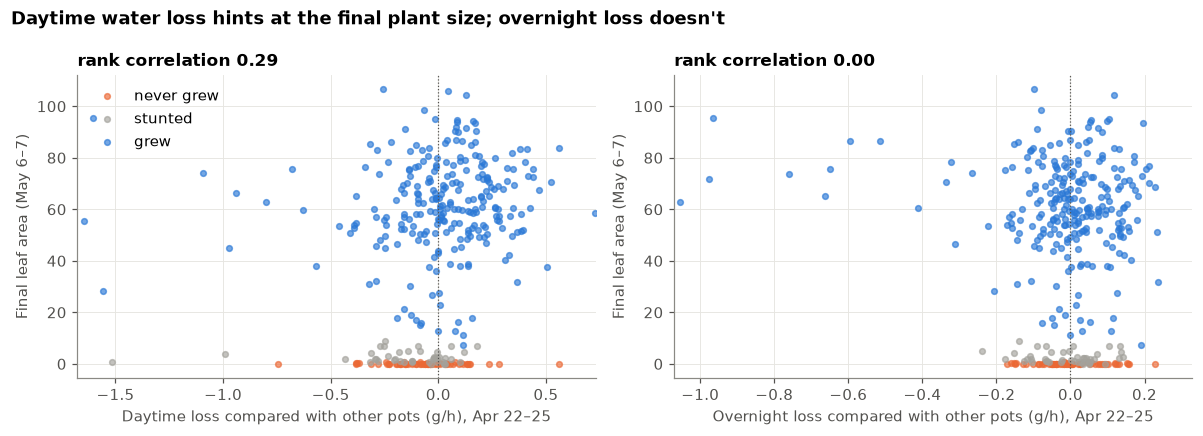

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, label in [(axes[0], "rel_loss_daytime", "Daytime loss compared with other pots (g/h), Apr 22–25"),
                       (axes[1], "rel_loss_overnight", "Overnight loss compared with other pots (g/h), Apr 22–25")]:
    for k in ["never grew", "stunted", "grew"]:
        m = plant_status.values == k
        ax.scatter(loss[col].values[m], y[m], s=14, alpha=0.65, color=STATUS_COLORS[k], label=k)
    ax.axvline(0, color=MUTED, lw=0.8, ls=":")
    lo, hi = loss[col].quantile([0.01, 0.99])
    ax.set_xlim(lo - 0.1, hi + 0.1)                      # a few odd pots fall outside; zoom in on the rest
    ax.set_xlabel(label); ax.set_ylabel("Final leaf area (May 6–7)")
    rho = pd.Series(loss[col].values).corr(pd.Series(y), method="spearman")   # the rank correlation
    ax.set_title(f"rank correlation {two_decimals(rho)}", fontsize=11)
axes[0].legend(loc="upper left")
fig.suptitle("Daytime water loss hints at the final plant size; overnight loss doesn't", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

There is a link, but it is weak, and only in the daytime gap, when leaves use the most water (Part A). Overnight the plant's share is too small to see. On Apr 22–25 most plants are still small, so most of each pot's loss is the soil drying out, which hides the plant's part.

A few pots have impossible values, such as a negative loss (the pot got heavier without being watered). These are probably scale or matching errors. We leave them in, because tree models are not thrown off by a few odd values.

1 · water loss: 8 inputs | linear: average miss 27.33 | forest: average miss 20.86, R² 0.33, average miss on plants that grew 18.29


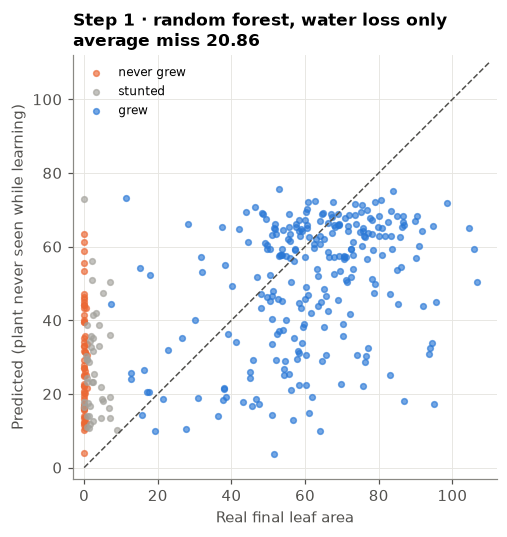

In [ ]:
# The inputs table grows step by step. Start with the water-loss inputs.
X = pd.DataFrame(index=plants)
X = X.join(loss)
pred = step("1 · water loss", X)
pred_vs_actual(pred, "Step 1 · random forest, water loss only", mae=ladder[-1]["forest MAE"]); plt.show()

Water loss alone already cuts the average miss by about a quarter compared with guessing the average. The forest does much better than linear regression here, because the link between water loss and final size is not a straight line (empty pots bunch up at low loss, grown plants spread out).

But the dots are spread widely around the dashed line. Water loss tells us roughly how big a plant is **now**, not how fast it will grow.

## Step 2 · Add water gain (the top-ups)

Inputs about the water the machine added, again from Apr 22–25:

| Input | What it means |
|---|---|
| `gain_per_topup` | typical grams added per top-up |
| `rel_gain_per_topup` | the same, compared with all the other pots in the same round of visits |
| `gain_g_per_day` | total grams added per day |
| `weight_before_watering` | typical pot weight before a top-up (how dry the pot gets) |

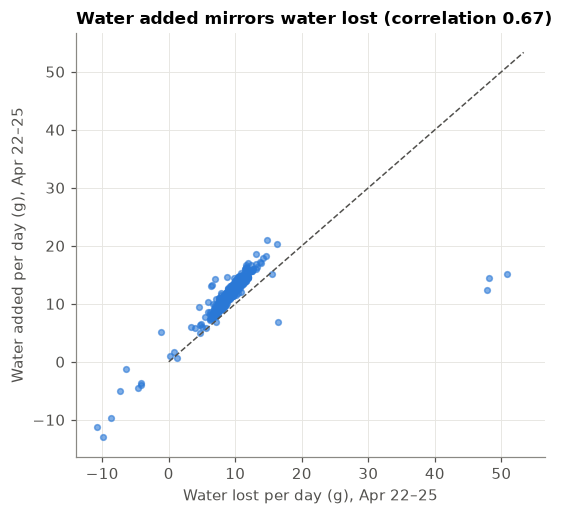

In [ ]:
def water_gain_features(cutoff, days=4):
    # Weigh-ins in the last few days before the cutoff, and how much water was added at each.
    recent = w[(w.datetime < cutoff) & (w.datetime >= cutoff - pd.Timedelta(days=days))].copy()
    recent["added"] = recent.weight_after_watering_g - recent.weight_g
    # Compared with the median of all pots in the same round of visits.
    recent["rel_added"] = recent.added - recent.groupby("round_id").added.transform("median")
    by_pot = recent.groupby("plant_id")
    return pd.DataFrame({
        "gain_per_topup": by_pot.added.median(),
        "rel_gain_per_topup": by_pot.rel_added.median(),
        "gain_g_per_day": by_pot.added.sum() / days,
        "weight_before_watering": by_pot.weight_g.median(),
    }).reindex(plants)


gain = water_gain_features(CUTOFF)

# Chart: water added per day against water lost per day, one dot per pot.
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(loss.loss_g_per_day, gain.gain_g_per_day, s=14, alpha=0.6, color=BLUE)
lim = [0, max(loss.loss_g_per_day.max(), gain.gain_g_per_day.max()) * 1.05]
ax.plot(lim, lim, color=MUTED, ls="--", lw=1)                     # the line where added = lost
corr = loss.loss_g_per_day.corr(gain.gain_g_per_day)
ax.set_xlabel("Water lost per day (g), Apr 22–25"); ax.set_ylabel("Water added per day (g), Apr 22–25")
ax.set_title(f"Water added mirrors water lost (correlation {corr:.2f})", fontsize=11)
plt.show()

The machine tops every pot back up to its own target weight, so **water added ≈ water lost**: most dots sit in a tight band along the dashed line. The few far from it are the odd pots mentioned above, and they are what pull the correlation down to 0.67. So water gain should add little that is new.

In [ ]:
X = X.join(gain)
pred = step("2 · + water gain", X)

2 · + water gain: 12 inputs | linear: average miss 27.17 | forest: average miss 20.66, R² 0.34, average miss on plants that grew 18.17


As expected, almost no change. Water gain carries mostly the same information as water loss.

## Step 3 · Add a straight-line growth trend

Now we look at the plant itself. For each plant we draw the best **straight line** through its daily leaf area over the last 7 days before the cutoff (Apr 19–25), and keep three numbers:

| Input | What it means |
|---|---|
| `line_slope` | how much the plant grew per day over the last week |
| `line_today` | where the line sits on Apr 25 (a smoothed "size today") |
| `line_forecast` | where the line would be on May 6–7 if it carried on straight |

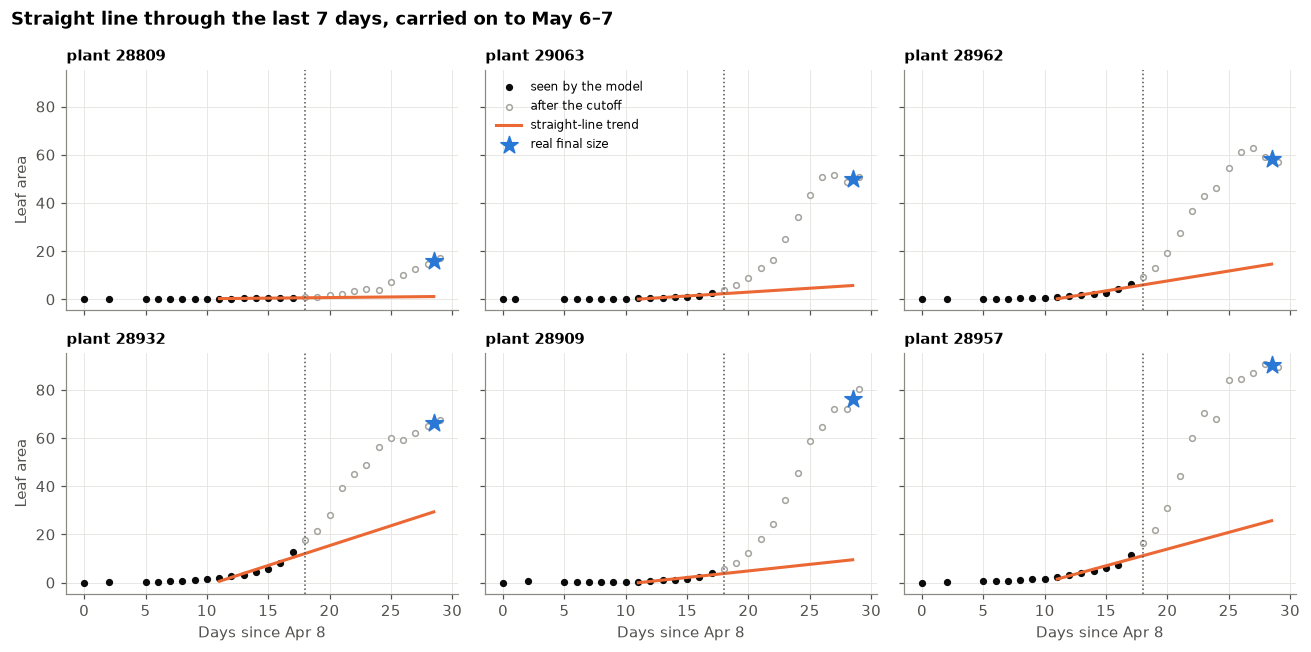

In [ ]:
PREDICT_AT = (TARGET_DAYS[0] - DAY0).days + 0.5          # the middle of May 6–7, in days since Apr 8


def linear_features(cutoff, days=7):
    # The last `days` days of leaf area before the cutoff.
    recent = daily[(daily.day < cutoff) & (daily.day >= cutoff - pd.Timedelta(days=days))]
    t_now = (cutoff - DAY0).days - 1                      # the last day the model can see
    rows = {}
    for pid, d in recent.groupby("plant_id"):
        if len(d) < 3:                                    # too few days to draw a line
            continue
        slope, intercept = np.polyfit(d.t, d.leaf_area, 1)   # the best straight line through the points
        rows[pid] = {"line_slope": slope, "line_today": intercept + slope * t_now,
                     "line_forecast": max(intercept + slope * PREDICT_AT, 0)}
    return pd.DataFrame.from_dict(rows, orient="index").reindex(plants)


line = linear_features(CUTOFF)

# Six example plants of different final sizes, to show what the growth inputs look like.
examples = pd.Series(y, index=plants)[grew].sort_values().iloc[[5, 50, 100, 150, 200, 240]].index


def show_examples(fitted_curve, title, label):
    # Chart: for each example plant, what the model saw (black), what came after (grey),
    # the fitted line or curve (orange) and the real final size (blue star).
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
    for ax, pid in zip(axes.flat, examples):
        d = daily[daily.plant_id == pid]
        seen, later = d[d.day < CUTOFF], d[d.day >= CUTOFF]
        ax.scatter(seen.t, seen.leaf_area, s=14, color=INK, label="seen by the model")
        ax.scatter(later.t, later.leaf_area, s=14, facecolor="white", edgecolor=GREY, label="after the cutoff")
        tt = np.linspace(0, PREDICT_AT, 200)
        curve = fitted_curve(pid, tt)
        if curve is not None:
            ax.plot(tt, curve, color=ORANGE, lw=2, label=label)
        ax.axvline((CUTOFF - DAY0).days, color=MUTED, ls=":", lw=1)
        ax.scatter([PREDICT_AT], [target[pid]], marker="*", s=140, color=BLUE, zorder=4, label="real final size")
        ax.set_title(f"plant {pid}", fontsize=10)
    for ax in axes[1]: ax.set_xlabel("Days since Apr 8")
    for ax in axes[:, 0]: ax.set_ylabel("Leaf area")
    axes[0, 1].legend(fontsize=8, loc="upper left")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold"); plt.tight_layout(); plt.show()


def line_curve(pid, tt):
    # The straight line for one plant, drawn from the first day it was fitted on.
    d = daily[(daily.plant_id == pid) & (daily.day < CUTOFF) & (daily.day >= CUTOFF - pd.Timedelta(days=7))]
    slope, intercept = np.polyfit(d.t, d.leaf_area, 1)
    return np.where(tt >= d.t.min(), intercept + slope * tt, np.nan)


show_examples(line_curve, "Straight line through the last 7 days, carried on to May 6–7", "straight-line trend")

The straight line captures **how fast** the plant is growing right now, which water loss could not. But carried on 11 days ahead, it falls short for almost every plant: growth is still speeding up on Apr 25, and a straight line can't speed up. (Top left is a late plant with nothing visible by Apr 25, so its line is flat.)

Used directly as the prediction, the line is weak:

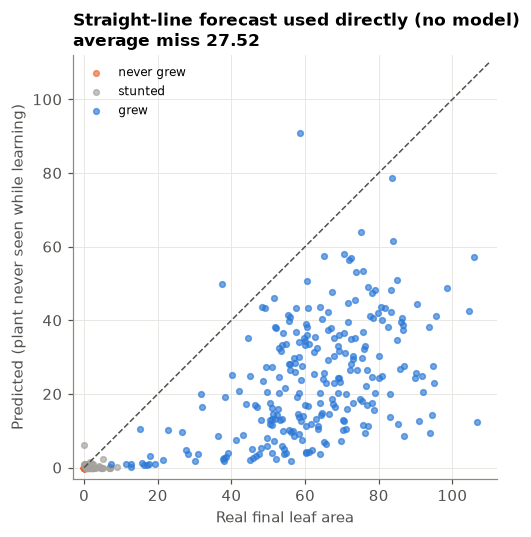

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
pred_vs_actual(line.line_forecast.fillna(0).values, "Straight-line forecast used directly (no model)", ax=ax); plt.show()

But as **inputs** to a model, the slope and the forecast carry exactly what was missing. The model learns how to correct them, for example "a plant growing this fast at this size usually ends up about here".

3 · + straight-line trend: 15 inputs | linear: average miss 19.11 | forest: average miss 9.16, R² 0.84, average miss on plants that grew 11.71


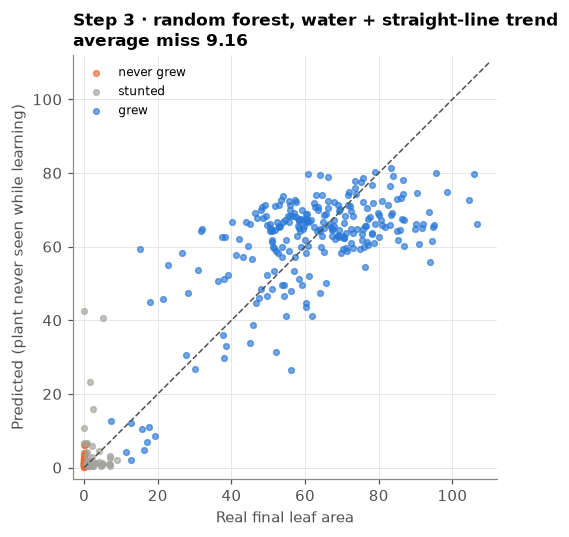

In [ ]:
X = X.join(line)
pred = step("3 · + straight-line trend", X)
pred_vs_actual(pred, "Step 3 · random forest, water + straight-line trend", mae=ladder[-1]["forest MAE"]); plt.show()

This is the biggest jump of the whole build: the average miss roughly halves. The plant's own recent growth tells us far more than its water use.

## Step 4 · Add an S-shaped growth curve

Plants grow in an S shape: a slow start, a fast middle, then levelling off. A standard curve with this shape (the **logistic curve**) is described by three numbers:

$$\text{leaf area on day } t = \frac{K}{1 + e^{-r\,(t - t_{mid})}}$$

- **K** is the size where the curve levels off (its guess of the final size);
- **r** is how steep the S is (how fast the plant grows);
- **t_mid** is the day of fastest growth.

| Input | What it means |
|---|---|
| `s_K` | the size where the curve levels off |
| `s_rate` | how steep the S is |
| `s_mid_day` | the day of fastest growth |
| `s_forecast` | where the curve is on May 6–7 |

Each plant's curve is fitted to **all** its daily leaf areas up to Apr 25. Plants with nothing visible yet (leaf area never reached 1) get a forecast of 0 and no curve numbers.

S-curve fitted for 243 plants; 117 had no visible plant yet; 0 fits failed; 227 fits ran into the upper limit of 150


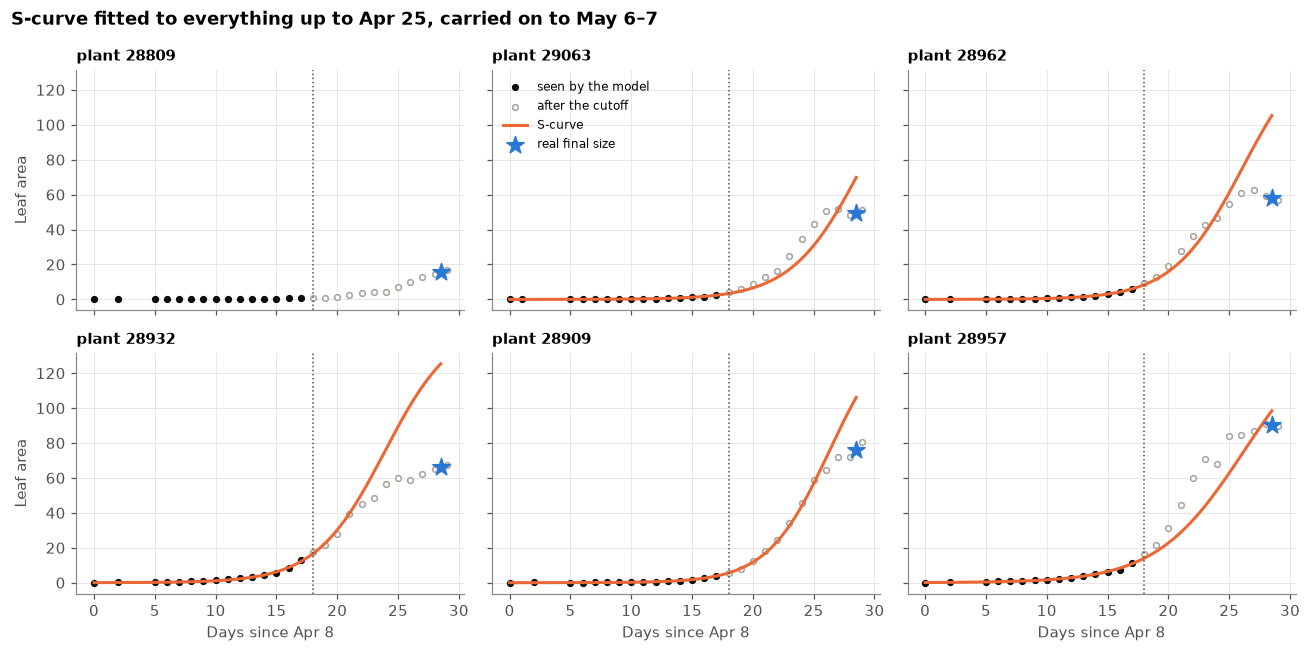

In [ ]:
def logistic(t, K, r, t_mid):
    # The S-shaped curve from the formula above.
    return K / (1 + np.exp(-r * (t - t_mid)))


def scurve_features(cutoff):
    seen = daily[daily.day < cutoff]
    t_now = (cutoff - DAY0).days - 1
    rows = {}
    for pid, d in seen.groupby("plant_id"):
        biggest = d.leaf_area.max()
        if biggest < 1:                                   # nothing visible yet: no curve to fit
            rows[pid] = {"s_K": np.nan, "s_rate": np.nan, "s_mid_day": np.nan, "s_forecast": 0.0}
            continue
        try:
            # Find the K, r and t_mid that fit this plant's points best.
            # Limits: K between half the biggest size seen and 150; r between 0.01 and 2; t_mid between day 0 and 60.
            (K, r, t_mid), _ = curve_fit(logistic, d.t, d.leaf_area, p0=[min(2 * biggest, 149), 0.3, t_now],
                                         bounds=([0.5 * biggest, 0.01, 0], [150, 2, 60]), maxfev=5000)
            rows[pid] = {"s_K": K, "s_rate": r, "s_mid_day": t_mid, "s_forecast": logistic(PREDICT_AT, K, r, t_mid)}
        except (RuntimeError, ValueError):                # the fit did not settle on an answer
            rows[pid] = {"s_K": np.nan, "s_rate": np.nan, "s_mid_day": np.nan, "s_forecast": np.nan}
    return pd.DataFrame.from_dict(rows, orient="index").reindex(plants)


scurve = scurve_features(CUTOFF)
no_plant_yet = (scurve.s_forecast == 0) & scurve.s_K.isna()
failed = scurve.s_forecast.isna()
at_ceiling = scurve.s_K > 149
print(f"S-curve fitted for {(~no_plant_yet & ~failed).sum()} plants; {no_plant_yet.sum()} had no visible plant yet; "
      f"{failed.sum()} fits failed; {at_ceiling.sum()} fits ran into the upper limit of 150")


def s_curve(pid, tt):
    p = scurve.loc[pid]
    return None if pd.isna(p.s_K) else logistic(tt, p.s_K, p.s_rate, p.s_mid_day)


show_examples(s_curve, "S-curve fitted to everything up to Apr 25, carried on to May 6–7", "S-curve")

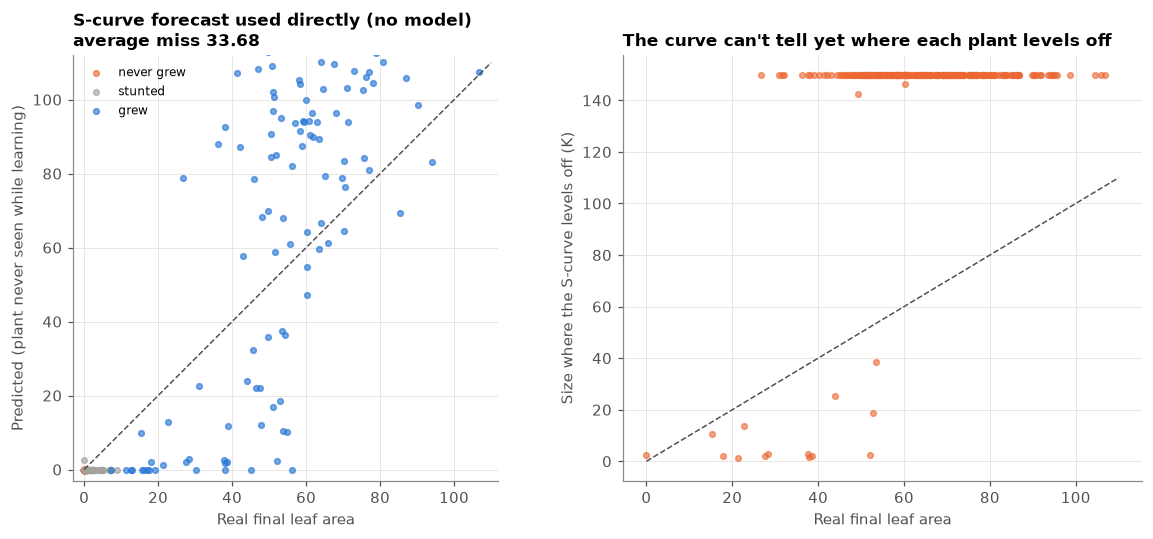

In [ ]:
# Left: the S-curve's forecast used directly as the prediction.
# Right: the curve's levelling-off size K against the real final size.
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
pred_vs_actual(scurve.s_forecast.fillna(0).values, "S-curve forecast used directly (no model)", ax=axes[0])
ok = scurve.s_K.notna().values
axes[1].scatter(y[ok], scurve.s_K.values[ok], s=14, alpha=0.6, color=ORANGE)
axes[1].plot([0, 110], [0, 110], color=MUTED, ls="--", lw=1)
axes[1].set_xlabel("Real final leaf area"); axes[1].set_ylabel("Size where the S-curve levels off (K)")
axes[1].set_title("The curve can't tell yet where each plant levels off", fontsize=11)
plt.tight_layout(); plt.show()

Used directly, the S-curve is even worse than the straight line, and now it **overshoots**. On Apr 25 the plants are still in the rising part of their S, before any levelling off, so the data can't pin down where they will level off. Almost every fit runs into the upper limit of 150 we allowed: the curve just keeps rising. The real levelling off (around 60 to 90) only shows up in May.

Still, the steepness and the day of fastest growth describe what stage the plant is at, and the forecast bends upwards where the straight line can't. That can help a model:

In [ ]:
X = X.join(scurve)
pred = step("4 · + S-curve", X)

4 · + S-curve: 19 inputs | linear: average miss 8.96 | forest: average miss 8.67, R² 0.85, average miss on plants that grew 11.05


A big gain for linear regression, which can't bend a straight line into a curve on its own, so the S-curve gives it that bend. A small gain for the forest, which could already learn some of it.

## Step 5 · Add the size history

The plant's real leaf area at a few points in the past week, and how long it has been visible:

| Input | What it means |
|---|---|
| `area_today` | leaf area on Apr 25 |
| `area_2d_ago`, `area_4d_ago`, `area_7d_ago` | leaf area 2, 4 and 7 days earlier |
| `growth_last_4d` | how much it grew over the last 4 days |
| `biggest_so_far` | the largest daily leaf area up to Apr 25 |
| `days_since_emerged` | days since its leaf area first reached 1 |

In [ ]:
def size_features(cutoff):
    # A table of daily leaf area up to the cutoff: one row per plant, one column per day.
    seen = daily[daily.day < cutoff].pivot(index="plant_id", columns="day", values="leaf_area").reindex(plants)
    last = cutoff - pd.Timedelta(days=1)                       # the last day the model can see
    col = lambda d: seen[d] if d in seen.columns else pd.Series(np.nan, index=plants)
    out = pd.DataFrame(index=plants)
    out["area_today"] = col(last)
    for lag in [2, 4, 7]:
        out[f"area_{lag}d_ago"] = col(last - pd.Timedelta(days=lag))
    out["growth_last_4d"] = out.area_today - out.area_4d_ago
    out["biggest_so_far"] = seen.max(axis=1)
    # The first day the plant was visible (leaf area of at least 1), if ever.
    visible = seen >= 1
    first_seen = visible.idxmax(axis=1).where(visible.any(axis=1))
    out["days_since_emerged"] = (last - pd.to_datetime(first_seen)).dt.days
    return out


size = size_features(CUTOFF)

# For reference: how well can we do from today's size alone (linear regression on area_today only)?
today_only, _ = score(size[["area_today"]].fillna(0), linear)
print(f"For reference, final size from today's size alone: average miss {today_only['MAE']:.2f}")

X = X.join(size)
pred = step("5 · + size history", X)

For reference, final size from today's size alone: average miss 18.47


5 · + size history: 26 inputs | linear: average miss 8.96 | forest: average miss 8.42, R² 0.86, average miss on plants that grew 10.87


Only a small gain: the straight line and the S-curve already sum up most of the size history.

## Step 6 · Add metal level and genotype

From the experiment design: which metal level the pot got (0 to 1000) and which of the 12 genotypes the plant is. Each genotype becomes its own yes/no column.

Before adding them, a look at what they do to final size. A simple box plot of final size per metal level would be misleading: at metal 500 and 1000 half the pots never grew, and their zeros drag the whole box down. That mixes two different questions: **did the plant grow at all?** and **how big did it get?** So we show them separately. The top row is the share of pots that grew; the bottom row is the final size of only the plants that grew.

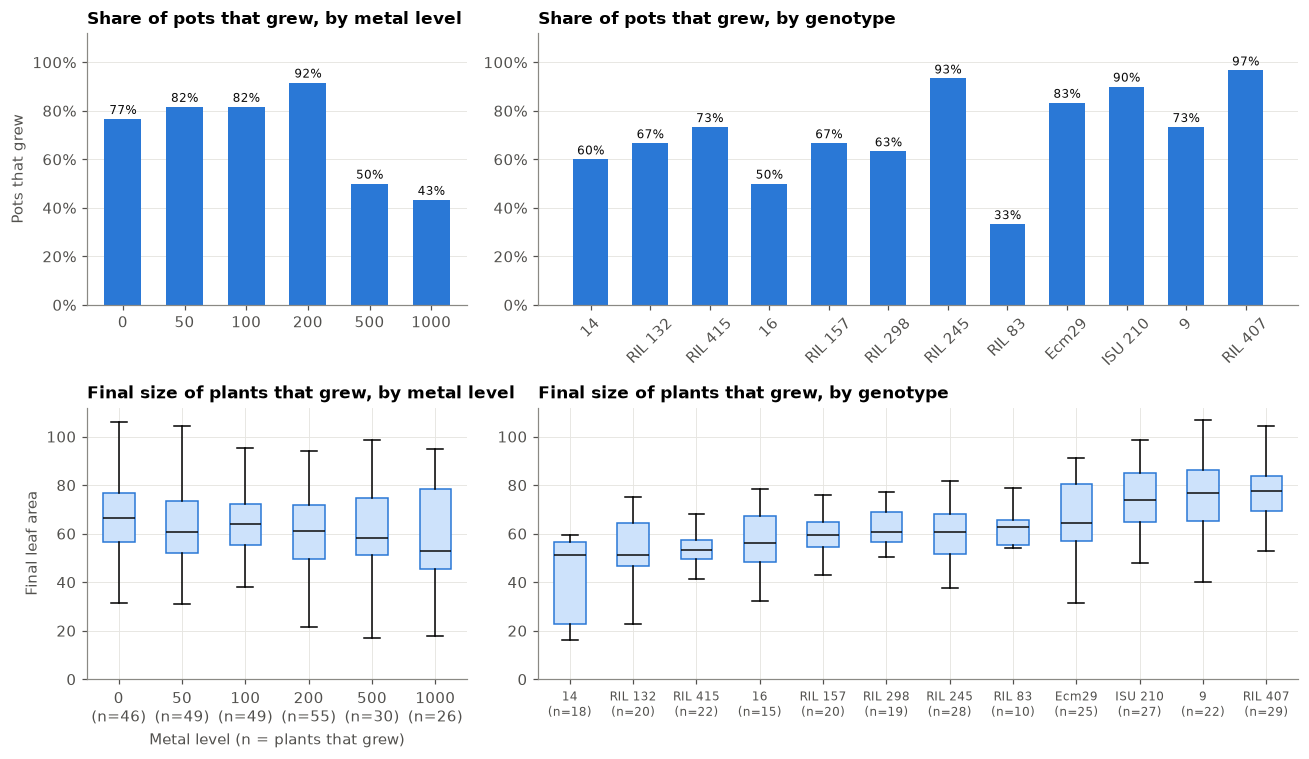

,pots,share that grew,"median size, all pots","median size, plants that grew"
metal,,,,
0,60,77%,60.1,66.6
50,60,82%,57.9,60.5
100,60,82%,60.3,64.0
200,60,92%,59.2,61.1
500,60,50%,8.1,58.1
1000,60,43%,3.2,52.8


In [ ]:
# Metal level as a number, plus one yes/no column per genotype.
design_inputs = pd.concat([design.loc[plants, ["metal"]],
                           pd.get_dummies(design.loc[plants, "genotype"], prefix="genotype", dtype=float)], axis=1)

# One row per plant: its metal level, genotype, final size, and whether it grew.
outcome = pd.DataFrame({"metal": design.loc[plants, "metal"].values, "genotype": design.loc[plants, "genotype"].values,
                        "final": y, "grew": grew})
grown_only = outcome[outcome.grew]
genotype_order = grown_only.groupby("genotype").final.median().sort_values().index   # smallest to biggest


def share_bars(ax, share, labels, title):
    # Bar chart of the share of pots that grew, with the % written on each bar.
    ax.bar(labels, share.values, color=BLUE, width=0.6)
    for i, v in enumerate(share.values):
        ax.text(i, v + 0.02, f"{v:.0%}", ha="center", fontsize=8, color=INK)
    ax.set_ylim(0, 1.12); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", visible=False); ax.set_title(title, fontsize=11)


def size_boxes(ax, groups, labels, title):
    # Box plot of final size; each box holds the middle half of the plants that grew.
    ax.boxplot(groups, positions=range(len(groups)), widths=0.5, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=INK))
    ax.set_xticks(range(len(groups)), labels); ax.set_ylim(0, 112); ax.set_title(title, fontsize=11)


fig, axes = plt.subplots(2, 2, figsize=(12, 7), gridspec_kw={"width_ratios": [1, 2]})
share_bars(axes[0, 0], outcome.groupby("metal").grew.mean().loc[metal_levels], [str(m) for m in metal_levels],
           "Share of pots that grew, by metal level")
share_bars(axes[0, 1], outcome.groupby("genotype").grew.mean().loc[genotype_order], list(genotype_order),
           "Share of pots that grew, by genotype")
size_boxes(axes[1, 0], [grown_only[grown_only.metal == m].final for m in metal_levels],
           [f"{m}\n(n={(grown_only.metal == m).sum()})" for m in metal_levels], "Final size of plants that grew, by metal level")
size_boxes(axes[1, 1], [grown_only[grown_only.genotype == gname].final for gname in genotype_order],
           [f"{gname}\n(n={(grown_only.genotype == gname).sum()})" for gname in genotype_order],
           "Final size of plants that grew, by genotype")
axes[0, 1].tick_params(axis="x", rotation=45); axes[1, 1].tick_params(axis="x", labelsize=8)
axes[1, 0].set_xlabel("Metal level (n = plants that grew)"); axes[1, 0].set_ylabel("Final leaf area")
axes[0, 0].set_ylabel("Pots that grew")
plt.tight_layout(); plt.show()

# The same numbers as a table, for the metal levels.
metal_table = pd.DataFrame({
    "pots": outcome.groupby("metal").size(),
    "share that grew": (outcome.groupby("metal").grew.mean() * 100).round(0).astype(int).astype(str) + "%",
    "median size, all pots": outcome.groupby("metal").final.median().round(1),
    "median size, plants that grew": grown_only.groupby("metal").final.median().round(1),
})
metal_table

- **The metal mainly decides whether a plant grows.** At metal 0–200, 77–92% of pots grew; at 500 only 50%, and at 1000 only 43%.
- **Plants that do grow at high metal are only somewhat smaller.** The typical grown plant ends at about 53 at metal 1000, against 61–67 at the low levels. Counting all pots, the medians at 500 and 1000 drop to 8 and 3, but that drop comes from the pots that failed, not from small plants.
- The same goes for genotypes: some (like RIL 83) mostly fail, while others fail rarely and grow big.
- One caution: the plants that survive high metal may be the most tolerant individuals, so they can look better than a typical plant would.

Now we add metal level and genotype to the model:

In [ ]:
X = X.join(design_inputs)
pred = step("6 · + metal level and genotype", X)

6 · + metal level and genotype: 39 inputs | linear: average miss 8.45 | forest: average miss 7.84, R² 0.88, average miss on plants that grew 10.08


A clear gain, mostly for the plants that grew: the genotype tells the model how likely this kind of plant is to grow and how big it tends to get, which no early measurement shows.

## Step 7 · Add leaf shape and colour

From the photos of the last 2 days before the cutoff, only where a plant is visible (leaf area of at least 1):
- **shape**: outline length, the area of the outline with its dents filled in, roundness, compactness, the height and width of the box around the plant, and solidity (how much of that filled-in outline is really leaf);
- **colour**: hue, saturation, lightness, green-red and blue-yellow balance, and two greenness scores.

Near-empty photos can give extreme shape values (roundness can reach 100 million), so each input is capped at its 1st and 99th percentile.

In [ ]:
def shape_colour_features(cutoff):
    # Photos of the last 2 days before the cutoff that show a plant.
    recent = photos[(photos.datetime < cutoff) & (photos.datetime >= cutoff - pd.Timedelta(days=2)) & (photos.area_mm2 >= 1)]
    recent = recent.assign(solidity=recent.area_mm2 / recent.convex_area_mm2)
    # One value per plant (the median of those photos), with extreme values capped.
    out = recent.groupby("plant_id")[SHAPE + COLOUR + ["solidity"]].median().reindex(plants)
    return out.clip(out.quantile(0.01), out.quantile(0.99), axis=1)


shape_colour = shape_colour_features(CUTOFF)
X = X.join(shape_colour)
pred = step("7 · + shape and colour", X)

7 · + shape and colour: 53 inputs | linear: average miss 8.47 | forest: average miss 7.78, R² 0.88, average miss on plants that grew 10.00


Again no real change for these two models. We'll see below whether the final model uses them.

## What each step bought

The chart below puts all the steps together. Each dot is the average miss after adding that group of inputs.

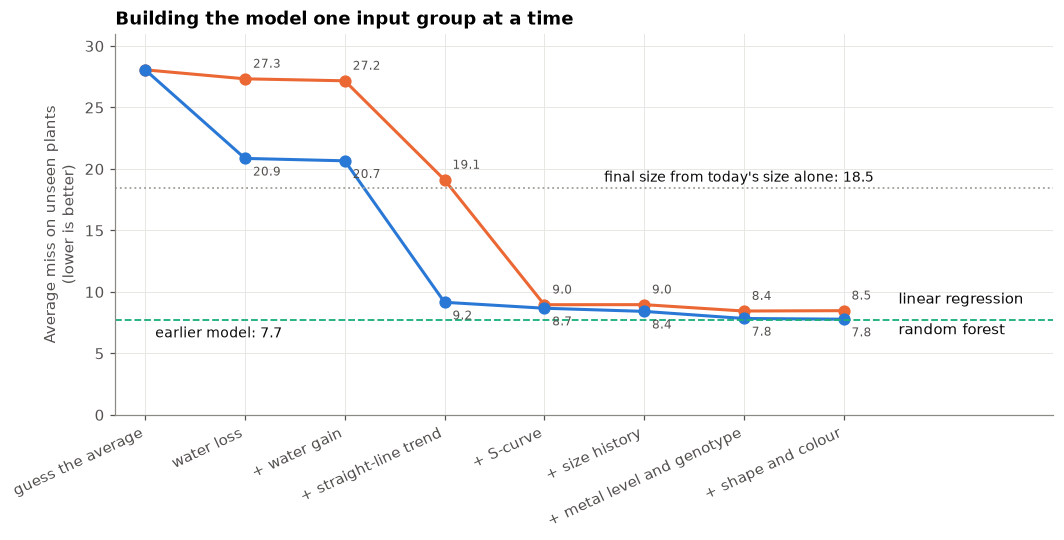

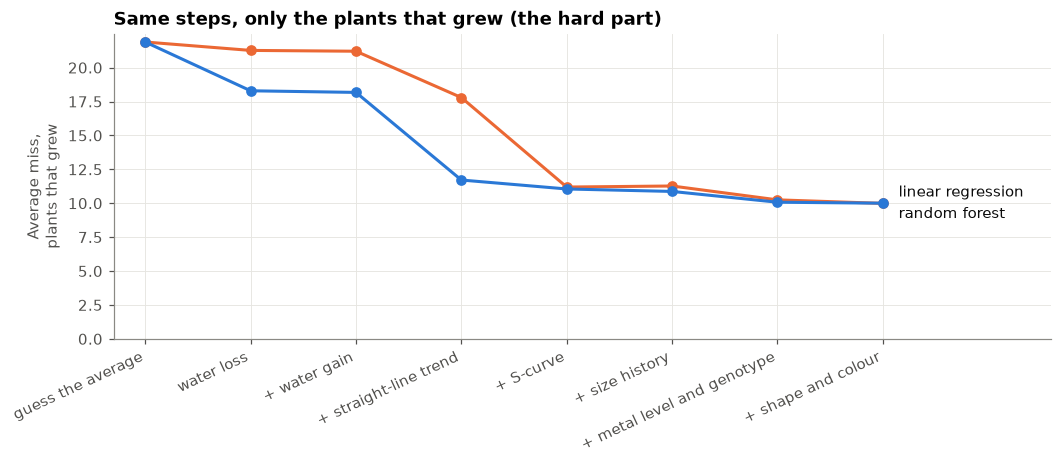

,step,inputs,linear MAE,forest MAE,forest R2,linear MAE (grew),forest MAE (grew)
0,0 · guess the average,0,28.06,28.06,-0.01,21.89,21.89
1,1 · water loss,8,27.33,20.86,0.33,21.27,18.29
2,2 · + water gain,12,27.17,20.66,0.34,21.21,18.17
3,3 · + straight-line trend,15,19.11,9.16,0.84,17.79,11.71
4,4 · + S-curve,19,8.96,8.67,0.85,11.19,11.05
5,5 · + size history,26,8.96,8.42,0.86,11.27,10.87
6,6 · + metal level and genotype,39,8.45,7.84,0.88,10.25,10.08
7,7 · + shape and colour,53,8.47,7.78,0.88,9.99,10.00


In [ ]:
lad = pd.DataFrame(ladder)
xs = np.arange(len(lad))
step_names = [s.split(" · ")[1] for s in lad.step]

# Chart 1: average miss on all plants, for both kinds of model, after each step.
fig, ax = plt.subplots(figsize=(11, 4.5))
for col, color, name, nudge in [("linear MAE", ORANGE, "linear regression", 0.9), ("forest MAE", BLUE, "random forest", -0.9)]:
    ax.plot(xs, lad[col], marker="o", ms=7, lw=2, color=color)
    ax.text(xs[-1] + 0.55, lad[col].iloc[-1] + nudge, name, va="center", color=INK)
    for x_, v in zip(xs[1:], lad[col].iloc[1:]):
        ax.text(x_ + 0.08, v + (0.9 if color == ORANGE else -1.4), f"{v:.1f}", ha="left", fontsize=8, color=MUTED)
# ax.axhline(7.7, color=AQUA, ls="--", lw=1.2)
# ax.text(0.1, 7.7 - 1.4, "earlier model: 7.7", color=INK, fontsize=9)
ax.axhline(today_only["MAE"], color=GREY, ls=":", lw=1.2)
ax.text(4.6, today_only["MAE"] + 0.5, f"final size from today's size alone: {today_only['MAE']:.1f}", color=INK, fontsize=9)
ax.set_xticks(xs, step_names, rotation=25, ha="right")
ax.set_ylabel("Average miss on unseen plants\n(lower is better)"); ax.set_ylim(0, 31); ax.set_xlim(-0.3, len(lad) + 1.1)
ax.set_title("Building the model one input group at a time")
plt.show()

# Chart 2: the same, only for the plants that grew.
fig, ax = plt.subplots(figsize=(11, 3.6))
for col, color, name, nudge in [("linear MAE (grew)", ORANGE, "linear regression", 0.8),
                                ("forest MAE (grew)", BLUE, "random forest", -0.8)]:
    ax.plot(xs, lad[col], marker="o", ms=6, lw=2, color=color)
    ax.text(xs[-1] + 0.15, lad[col].iloc[-1] + nudge, name, va="center", color=INK)
ax.set_xticks(xs, step_names, rotation=25, ha="right")
ax.set_ylabel("Average miss,\nplants that grew"); ax.set_ylim(0, None); ax.set_xlim(-0.3, len(lad) + 0.6)
ax.set_title("Same steps, only the plants that grew (the hard part)")
plt.show()
lad.round(2)

## Step 8 · Try different kinds of model

All the inputs are in. Now we compare a few kinds of model on the same inputs:
- **extra trees**: like a random forest, but each tree chooses its rules more randomly, which often makes it a bit smoother;
- **gradient boosting**: trees built one after another, each one fixing the mistakes of the ones before;
- **an average of three models** (linear regression + random forest + extra trees). Averaging tends to help because different models make different mistakes.

linear regression                          average miss 8.47  R² 0.86  average miss on plants that grew 9.99


random forest                              average miss 7.78  R² 0.88  average miss on plants that grew 10.00


extra trees                                average miss 7.49  R² 0.89  average miss on plants that grew 9.45


gradient boosting                          average miss 8.11  R² 0.87  average miss on plants that grew 10.44


average of linear + forest + extra trees   average miss 7.50  R² 0.89  average miss on plants that grew 9.35


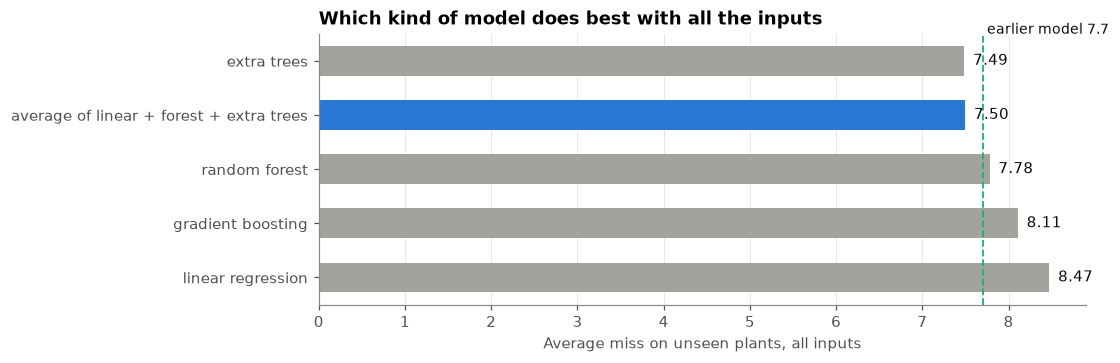

In [ ]:
extra = make_pipeline(fill_blanks(), ExtraTreesRegressor(n_estimators=500, min_samples_leaf=2, max_features=0.5,
                                                         n_jobs=-1, random_state=0))
boost = make_pipeline(fill_blanks(), HistGradientBoostingRegressor(max_iter=400, learning_rate=0.03, min_samples_leaf=8,
                                                                   l2_regularization=1.0, random_state=0))
# Run all three models and average their predictions.
average3 = VotingRegressor([("linear", linear), ("forest", forest), ("extra", extra)])

candidates = {"linear regression": linear, "random forest": forest, "extra trees": extra,
              "gradient boosting": boost, "average of linear + forest + extra trees": average3}
compare = {}
for name, model in candidates.items():
    compare[name], _ = score(X, model)
    print(f"{name:42s} average miss {compare[name]['MAE']:.2f}  R² {compare[name]['R2']:.2f}  "
          f"average miss on plants that grew {compare[name]['MAE grew']:.2f}")

# Chart: average miss of each kind of model, best at the top.
cmp = pd.DataFrame(compare).T.sort_values("MAE")
fig, ax = plt.subplots(figsize=(9, 3.2))
CHOSEN = "average of linear + forest + extra trees"          # our final model, shown in blue
ax.barh(cmp.index[::-1], cmp.MAE[::-1], color=[BLUE if name == CHOSEN else GREY for name in cmp.index[::-1]], height=0.55)
for i, v in enumerate(cmp.MAE[::-1]):
    ax.text(v + 0.1, i, f"{v:.2f}", va="center", color=INK)
ax.axvline(7.7, color=AQUA, ls="--", lw=1.2); ax.text(7.75, len(cmp) - 0.5, "earlier model 7.7", fontsize=9, color=INK)
ax.set_xlabel("Average miss on unseen plants, all inputs"); ax.grid(axis="y", visible=False)
ax.set_title("Which kind of model does best with all the inputs")
plt.show()

Extra trees on its own and the average of the three models are tied (7.49 and 7.50; a gap of 0.01 is just noise). We pick **the average** (blue) as the final model, because it does better on the plants that grew (9.35 against 9.45), the harder part, and it doesn't lean on a single model.

### What the final model relies on

To see what each group of inputs contributes to the **final** model, we take out one group at a time and measure how much worse the model gets. A big increase means the model really needs that group. This is not the same as the steps above, where each group's gain depended on what was already in.

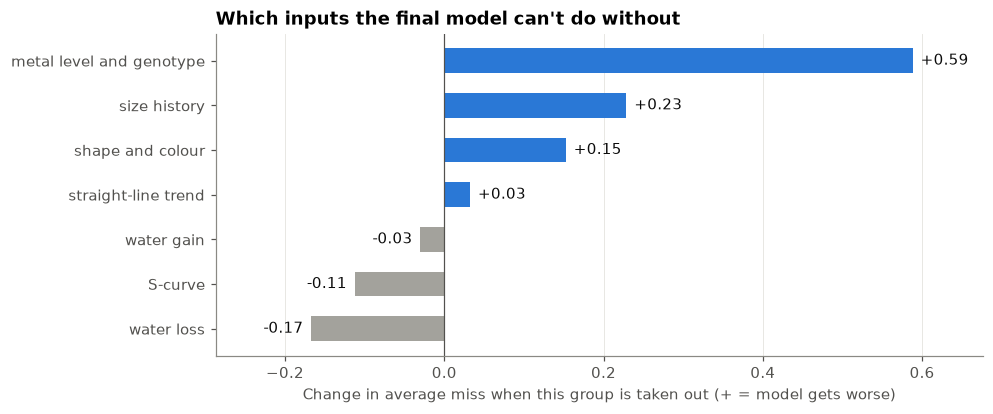

In [ ]:
final = average3
input_groups = {
    "water loss": list(loss.columns), "water gain": list(gain.columns), "straight-line trend": list(line.columns),
    "S-curve": list(scurve.columns), "size history": list(size.columns),
    "metal level and genotype": list(design_inputs.columns), "shape and colour": list(shape_colour.columns),
}

# Score with everything, then with each group taken out, and note the difference.
full_scores, _ = score(X, final, repeats=2)
drop_cost = {name: score(X.drop(columns=cols), final, repeats=2)[0]["MAE"] - full_scores["MAE"]
             for name, cols in input_groups.items()}
drop_cost = pd.Series(drop_cost).sort_values()

# Chart: blue = the model gets worse without this group (it needs it); grey = it gets better (the group was noise).
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(drop_cost.index, drop_cost.values, color=[BLUE if v > 0 else GREY for v in drop_cost.values], height=0.55)
for i, v in enumerate(drop_cost.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", color=INK)
ax.axvline(0, color=MUTED, lw=0.8); ax.grid(axis="y", visible=False)
lo = min(drop_cost.min(), 0); ax.set_xlim(lo * 1.6 - 0.02, drop_cost.max() * 1.15)
ax.set_xlabel("Change in average miss when this group is taken out (+ = model gets worse)")
ax.set_title("Which inputs the final model can't do without")
plt.show()

- **Metal level and genotype** matter most: they carry information that no early measurement has.
- **Size history** and **shape and colour** still add something.
- The **straight-line trend** now adds only a little: once the size history is in, it repeats much of the same information.
- Taking out **water loss**, **water gain** or the **S-curve** makes the final model slightly *better* (grey bars). They helped a lot early on, when nothing better was in. Now the plant's own size and growth, measured straight from the photos, already say everything they said, and they mostly add noise.

## Step 9 · Remove what no longer helps

So the last step is to take out the groups whose removal helped, and score the leaner model properly (3 repeats).

In [ ]:
not_needed = [name for name, cost in drop_cost.items() if cost < 0]
X_lean = X.drop(columns=[c for name in not_needed for c in input_groups[name]])
lean_scores, _ = score(X_lean, final)
all_scores, _ = score(X, final)
print(f"Taken out: {', '.join(not_needed)}")
print(f"All {X.shape[1]} inputs:  average miss {all_scores['MAE']:.2f}, R² {all_scores['R2']:.2f}, "
      f"plants that grew {all_scores['MAE grew']:.2f}")
print(f"Lean {X_lean.shape[1]} inputs: average miss {lean_scores['MAE']:.2f}, R² {lean_scores['R2']:.2f}, "
      f"plants that grew {lean_scores['MAE grew']:.2f}")

# Keep whichever set of inputs scored better.
X_final = X_lean if lean_scores["MAE"] < all_scores["MAE"] else X
print(f"The final model uses {'the lean' if X_final is X_lean else 'all'} inputs ({X_final.shape[1]})")
ladder.append({"step": "9 · drop inputs that no longer help", "inputs": X_final.shape[1], "linear MAE": np.nan,
               "forest MAE": np.nan, "forest R2": np.nan, "linear MAE (grew)": np.nan, "forest MAE (grew)": np.nan,
               "final model MAE": min(lean_scores["MAE"], all_scores["MAE"])})

Taken out: water loss, S-curve, water gain
All 53 inputs:  average miss 7.50, R² 0.89, plants that grew 9.35
Lean 37 inputs: average miss 7.28, R² 0.89, plants that grew 9.12
The final model uses the lean inputs (37)


One caution: we chose which groups to take out using the same test splits we score on, which flatters the lean score a little. The difference between the two is small either way. The plain conclusion: **water loss and water gain don't help once the photos show the plant's own growth.**

## The final model, in detail

Final model: average miss 7.28, R² 0.89
  pots that never grew: average miss 2.03
  plants that grew: average miss 9.04, typical miss 11% of the plant's size, 65% within 10 units, R² among them 0.60


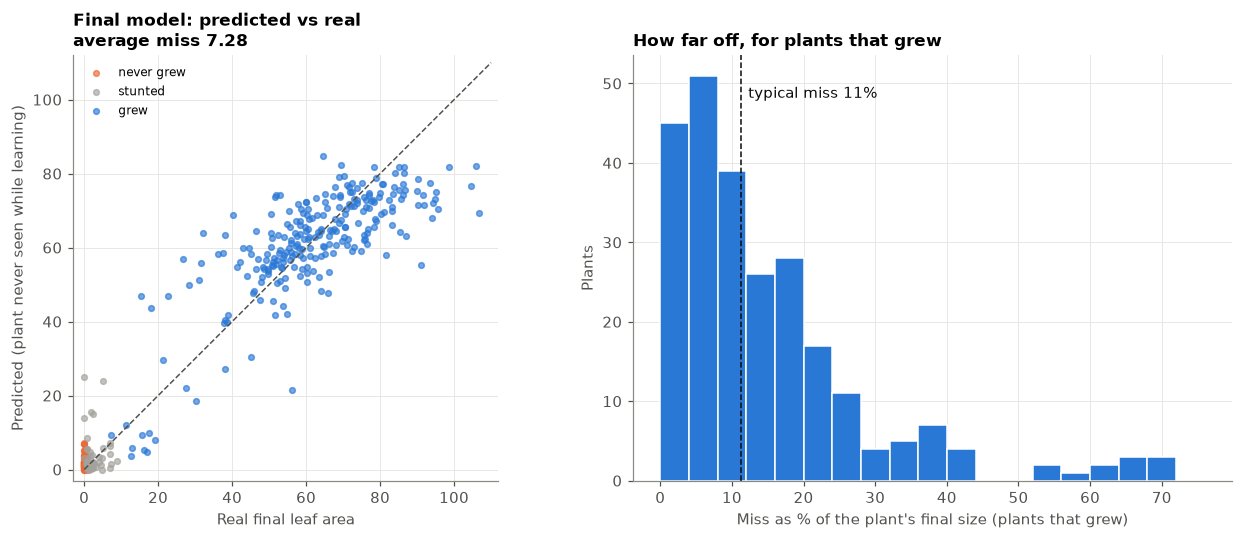

In [ ]:
final_scores, final_pred = score(X_final, final)
grew_err = np.abs(final_pred - y)[grew]              # how far off, for each plant that grew
pct_err = grew_err / y[grew]                         # the same, as a share of the plant's real size
print(f"Final model: average miss {final_scores['MAE']:.2f}, R² {final_scores['R2']:.2f}")
print(f"  pots that never grew: average miss {np.abs(final_pred - y)[plant_status.values == 'never grew'].mean():.2f}")
print(f"  plants that grew: average miss {grew_err.mean():.2f}, typical miss {np.median(pct_err):.0%} of the plant's size, "
      f"{(grew_err <= 10).mean():.0%} within 10 units, R² among them {r2_score(y[grew], final_pred[grew]):.2f}")

# Left: predicted against real size. Right: how far off, as a % of the plant's size, for plants that grew.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pred_vs_actual(final_pred, "Final model: predicted vs real", ax=axes[0], mae=final_scores["MAE"])
axes[1].hist(pct_err * 100, bins=np.arange(0, 80, 4), color=BLUE, edgecolor="white")
axes[1].axvline(np.median(pct_err) * 100, color=INK, ls="--", lw=1)
axes[1].text(np.median(pct_err) * 100 + 1, axes[1].get_ylim()[1] * 0.9, f"typical miss {np.median(pct_err):.0%}", color=INK)
axes[1].set_xlabel("Miss as % of the plant's final size (plants that grew)"); axes[1].set_ylabel("Plants")
axes[1].set_title("How far off, for plants that grew", fontsize=11)
plt.tight_layout(); plt.show()

Where does the model struggle? Here is the average miss by metal level and by genotype:

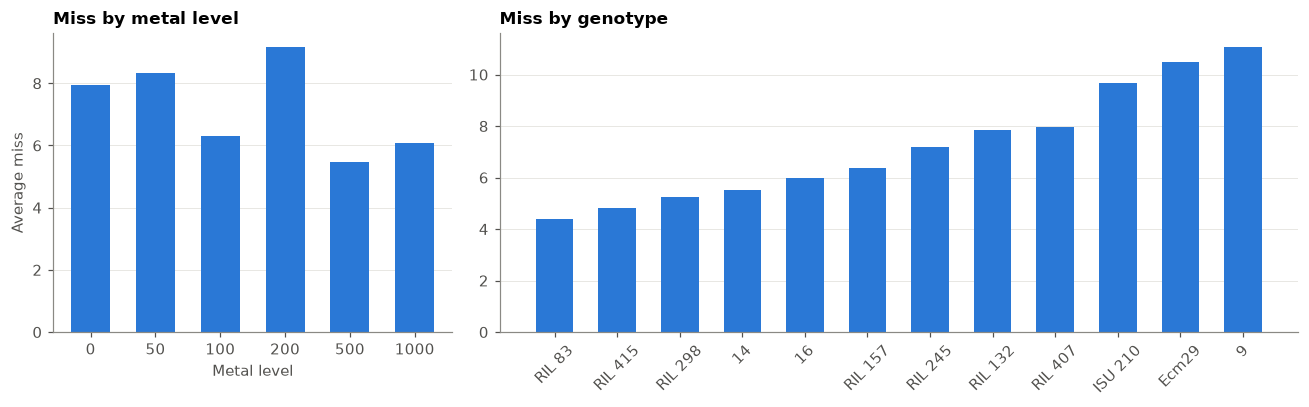

In [ ]:
err = pd.DataFrame({"abs_error": np.abs(final_pred - y), "metal": design.loc[plants, "metal"].values,
                    "genotype": design.loc[plants, "genotype"].values, "grew": grew})
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2]})
by_metal = err.groupby("metal").abs_error.mean()
axes[0].bar([str(m) for m in by_metal.index], by_metal.values, color=BLUE, width=0.6)
axes[0].set_xlabel("Metal level"); axes[0].set_ylabel("Average miss"); axes[0].set_title("Miss by metal level", fontsize=11)
by_genotype = err.groupby("genotype").abs_error.mean().sort_values()
axes[1].bar(by_genotype.index, by_genotype.values, color=BLUE, width=0.6)
axes[1].tick_params(axis="x", rotation=45); axes[1].set_title("Miss by genotype", fontsize=11)
for ax in axes: ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

High-metal pots have a **smaller** miss: many of them never grow, and those are easy to predict. The miss is biggest for genotypes whose plants end up big or very mixed in size (9, Ecm29, ISU 210). It is smallest for genotypes whose pots mostly fail (RIL 83, where only a third grew) or whose plants end at a similar size (RIL 415, RIL 298).

### Does it work on a genotype it has never seen?

Here the model learns from 11 genotypes and is tested on the 12th, rotating through all 12.

In [ ]:
# GroupKFold(12) keeps all plants of one genotype together, so the test genotype is never seen while learning.
geno_scores, geno_pred = score(X_final, final, repeats=1, cv=GroupKFold(12), groups=design.loc[plants, "genotype"].values)
print(f"Unseen genotype: average miss {geno_scores['MAE']:.2f}, R² {geno_scores['R2']:.2f}, "
      f"plants that grew {geno_scores['MAE grew']:.2f}")
print(f"(unseen plants of genotypes it has seen: average miss {final_scores['MAE']:.2f})")

Unseen genotype: average miss 8.93, R² 0.85, plants that grew 11.47
(unseen plants of genotypes it has seen: average miss 7.28)


### How early can we predict?

Everything above used Apr 25 as the last day the model can see. Below, all the inputs are rebuilt for other cutoffs, from Apr 16 (3 weeks before the end) to May 1 (5 days before), and the final model is scored again each time.

last day seen Apr 16 (20 days ahead): final model 14.75, today's size alone 19.79


last day seen Apr 19 (17 days ahead): final model 11.25, today's size alone 18.94


last day seen Apr 22 (14 days ahead): final model 9.30, today's size alone 19.31


last day seen Apr 25 (11 days ahead): final model 7.25, today's size alone 18.44


last day seen Apr 28 (8 days ahead): final model 6.61, today's size alone 16.64


last day seen May 01 (5 days ahead): final model 5.36, today's size alone 12.39


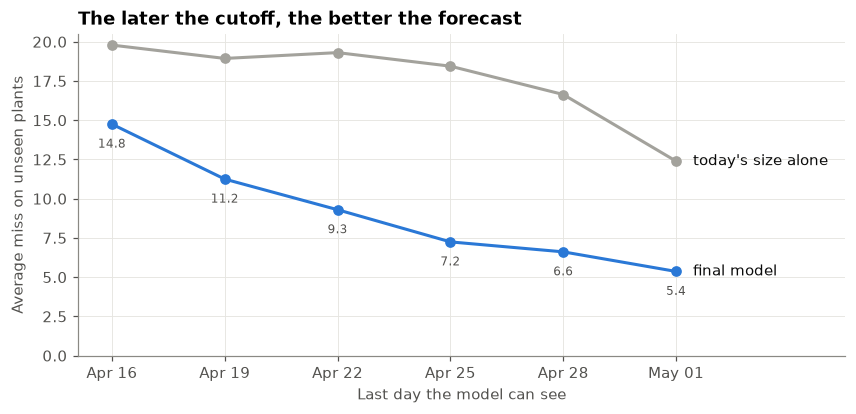

In [ ]:
def build_inputs(cutoff):
    # All the input groups, rebuilt using only data from before `cutoff`.
    return pd.concat([water_loss_features(cutoff), water_gain_features(cutoff), linear_features(cutoff),
                      scurve_features(cutoff), size_features(cutoff), design_inputs,
                      shape_colour_features(cutoff)], axis=1)


cutoffs = pd.to_datetime(["2026-04-17", "2026-04-20", "2026-04-23", "2026-04-26", "2026-04-29", "2026-05-02"])
by_cutoff = []
for c in cutoffs:
    Xc = build_inputs(c).reindex(columns=X_final.columns)    # the same inputs as the final model
    s, _ = score(Xc, final, repeats=2)
    t, _ = score(size_features(c)[["area_today"]].fillna(0), linear, repeats=2)
    by_cutoff.append({"last day seen": (c - pd.Timedelta(days=1)).strftime("%b %d"), "days ahead": (TARGET_DAYS[0] - c).days + 1,
                      "final model MAE": s["MAE"], "today's size alone MAE": t["MAE"]})
    print(f"last day seen {by_cutoff[-1]['last day seen']} ({by_cutoff[-1]['days ahead']} days ahead): "
          f"final model {s['MAE']:.2f}, today's size alone {t['MAE']:.2f}")
by_cutoff = pd.DataFrame(by_cutoff)

# Chart: average miss against the last day the model can see.
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(by_cutoff["last day seen"], by_cutoff["today's size alone MAE"], marker="o", color=GREY, lw=2)
ax.plot(by_cutoff["last day seen"], by_cutoff["final model MAE"], marker="o", color=BLUE, lw=2)
ax.text(len(by_cutoff) - 0.85, by_cutoff["today's size alone MAE"].iloc[-1], "today's size alone", va="center", color=INK)
ax.text(len(by_cutoff) - 0.85, by_cutoff["final model MAE"].iloc[-1], "final model", va="center", color=INK)
for i, r in by_cutoff.iterrows():
    ax.text(i, r["final model MAE"] - 1.5, f"{r['final model MAE']:.1f}", ha="center", fontsize=8, color=MUTED)
ax.set_xlim(-0.3, len(by_cutoff) + 0.5); ax.set_ylim(0, None)
ax.set_xlabel("Last day the model can see"); ax.set_ylabel("Average miss on unseen plants")
ax.set_title("The later the cutoff, the better the forecast")
plt.show()

In [ ]:
pd.DataFrame({"plant_id": plants, "genotype": design.loc[plants, "genotype"].values,
              "metal": design.loc[plants, "metal"].values, "status": plant_status.values,
              "actual_final_leaf_area": y, "predicted": final_pred}).to_csv(OUT / "predictions_cutoff_apr25.csv", index=False)
pd.DataFrame(ladder).to_csv(OUT / "feature_ladder.csv", index=False)
by_cutoff.to_csv(OUT / "error_by_cutoff.csv", index=False)
print("saved to", OUT.resolve())

saved to C:\Users\kolaw\Downloads\Pennycrest\work2\outputs


---
# Summary

## Part A · What uses the water

**How the gaps were built.** Pots were weighed three times a day: in the morning (about 07:30–11:00), the afternoon (about 16:00–17:00) and late at night (about 23:00–00:00). A gap runs from the weight right after a top-up to the weight at the pot's next visit. Gaps are named after when they start and end: daytime, evening and overnight. Only Apr 21–30 is used, and gaps that skipped a visit are dropped.

**What takes the water** (grown pots, Apr 21–30; baseline from all 62 empty pots):

| Gap | Total loss | Soil evaporation | Plant use |
|---|---|---|---|
| daytime | 1.09 g/h | 0.67 g/h (61%) | 0.43 g/h (39%) |
| evening | 0.60 g/h | 0.43 g/h (71%) | 0.17 g/h (29%) |
| overnight | 0.34 g/h | 0.26 g/h (74%) | 0.09 g/h (26%) |

- The plant's share grows fast: about 2% of the daily loss on Apr 21–23 (seedlings), 56% on Apr 27–29, when the plant takes more than the soil in the daytime gap.
- Daytime loss is high for two reasons: bare soil dries 2.7 times faster by day than overnight (the room under the lights), and each piece of leaf uses 4.1 times more water by day (leaf pores open in light and close in the dark).
- Plant use starts at about 0 for tiny plants and rises with leaf area, which shows that "pot minus empty pot" is a fair measure.
- The daytime split and the 56% are steady whichever empty pots set the baseline (low or high metal). The **evening and overnight split is not**: it moves by up to 13 percentage points, so treat those two numbers as rough.
- The metal mainly decides whether a plant grows (43–50% grew at metal 500–1000, 77–92% at lower levels). We found no clear effect on soil drying, or on water use per piece of leaf once plant size is allowed for. With few pots in some groups, a small effect can't be ruled out.

## Part B · How big each plant will get

**Final model:** the average of linear regression, random forest and extra trees, using 37 inputs: the straight-line trend, size history, metal level and genotype, and leaf shape and colour. **Where the pot sat is not used.** Using data up to Apr 25, it predicts each plant's leaf area on May 6–7 with an **average miss of 7.28 on plants it never saw** (R² 0.89). For comparison: 28.1 for guessing the average, 18.5 for today's size alone, and 7.7 for the earlier model (which used pot position).

| Group | How well it does |
|---|---|
| Pots that never grew | average miss 2.0: predicted close to 0 |
| Plants that grew | average miss 9.0; typical miss 11% of the plant's size; 65% within 10 units; R² 0.60 among them |
| A genotype the model never saw | average miss 8.9 |

**What each step taught us** (random forest unless noted):

| Step | Average miss | Lesson |
|---|---|---|
| 0 · guess the average | 28.1 | the bar to beat |
| 1 · water loss | 20.9 | pots that lose more water by day hold bigger plants, but the signal is weak because the soil takes most of the water on Apr 22–25 (Part A) |
| 2 · + water gain | 20.7 | top-ups mirror losses, so almost nothing new |
| 3 · + straight-line trend | 9.2 | the biggest jump: how fast the plant is growing right now |
| 4 · + S-curve | 8.7 | used alone it overshoots (it can't tell yet where plants level off), but it gives linear regression the bend it lacks (19.1 → 9.0) |
| 5 · + size history | 8.4 | a small gain, mostly overlapping the trend |
| 6 · + metal level and genotype | 7.8 | a clear gain: how likely this kind of plant is to grow, and how big it gets, which no early measurement shows |
| 7 · + shape and colour | 7.8 | little change on its own |
| 8 · average of three models | 7.50 | tied with extra trees alone (7.49), but better on the plants that grew |
| 9 · drop water loss, water gain, S-curve | **7.28** | once the photos show the plant's growth, the water numbers add only noise |

**How early:** an average miss of 14.8 with data up to Apr 16 (20 days ahead), 11.2 by Apr 19, 9.3 by Apr 22, 7.2 by Apr 25, 6.6 by Apr 28 and 5.4 by May 1. At every cutoff it is well ahead of "today's size alone".